# Task 28 — Developer Q&A copilot: answer from the archive, cite every source, and know when an answer has gone stale

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [StackSample: 10% of Stack Overflow Q&A](https://www.kaggle.com/datasets/stackoverflow/stacksample) — 1.26 M questions (Aug 2008 – Oct 2016), their 2.0 M answers and 3.75 M tags, published by Stack Overflow under CC BY-SA 3.0
**Task family:** multi-label text classification, retrieval without an LLM, licence-compliant attribution · **Companion tasks:** `04_erp_document_rag.ipynb` (retrieval without an LLM), `03_complaint_triage_text.ipynb` (text classification and label drift)

---

## The task card

> **Board question.** *Our engineers ask about 150 data and database questions a week, and many have been answered before. If a copilot may only show earlier answers, each with the attribution the licence asks for, how often does it surface the thread a colleague would have pointed to, how many of its answers use an API that has since been removed, and does it save more time than it takes to read?*

**Business context.** A copilot in the chat tool or IDE answers at request time and the engineer decides whether to trust it: Session 01's *online prediction with a human in the loop*. The content is not ours (CC BY-SA 3.0), so attribution is a functional requirement; and the archive ages, so an answer right in 2012 may call an API that no longer exists. The public archive stands in for an internal one, alongside a legacy Q&A tool, chat platform and identity directory.

**What you will build from this notebook (see *Student tasks* at the end):**

1. the given **tag model**, packaged and reproducible, evaluated forward in time;
2. the given **retrieval copilot without an LLM**, packaged and reproducible: BM25 plus a reader that shows one attributed answer per thread, scored on a link-based golden set;
3. a **knowledge layer** (tag graph, versioned libraries, removed-API facts) and its ablation;
4. the **operational wrapper** and a one-page **recommendation to the engineering manager**, with the licence position.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | A copilot between the Q&A archive, chat and IDE; attribution as an integration requirement |
| 2 · MLOps | Forward-in-time evaluation; retrieval and attribution gates; drift and staleness monitoring |
| 3 · Semantic layer | Tag graph, versioned libraries and removed-API facts; the ablation |
| 4 · LLM/RAG | Retrieval without an LLM first; then RAG answers in which every claim cites its source |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. The baseline runs **without any LLM**, so retrieval quality is visible before generation hides it. Five traps are measured and flagged ⚠.

**Honesty note.** The data is **real**: public posts by real developers, so the problems (stale answers, votes that reward age, duplicates) are genuine, and so are the authors. The data holds their account numbers but not their names: the notebook credits authors by profile link and never prints a name. The link-based golden set is small and incomplete; the business constants are assumptions.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–2 | Dataset card and first look | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 3–6 | The tagger forward in time, BM25 retrieval and the attributed reader, the traps, the knowledge layer and the number of suggestions | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 7–10 | The archive drifting under the copilot, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 7 shows the drift your monitoring must catch. |

**What you need from Parts A and B**

- **Code to package:** `get_raw`, `clean`, `build_caches` and `load` (Section 1); `fit_tagger`, `predict_sets`, `tag_metrics` and `choose_threshold` (Section 3); `bm25_weights`, `query_text`, `search`, `pick_answer`, `attribution` and `ask` (Section 4); `query_tags`, `rerank` and `minutes_per_question` (Section 6); `psi_cat` for monitoring (Section 7).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** 158,542 questions and 265,090 answers in the slice, 1,100 golden-set rows; tag micro-F1 0.750 on 2015 – Oct 2016 (0.753 on 2014); pooled recall@5 0.229 on test with the adopted predicted-tag boost; one suggestion finding the linked thread for 13.8 % of answerable test questions, saving about 2.4 engineer-hours a week (≈ €146); stale top answers cut from 9.1 % to 5.7 % by the fresh-first reader.
- **Runtime:** about 2–3 minutes on a laptop (112 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
%matplotlib inline
import os, re, gc, time, html, json, hashlib, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import scipy.sparse as sp
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
from IPython.display import display
from sklearn.feature_extraction.text import TfidfTransformer, CountVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import f1_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140); pd.set_option("display.max_colwidth", 90)

# ---- parameters -------------------------------------------------------------
SEED = 3217
KAGGLE_HANDLE = "stackoverflow/stacksample"
SAMPLE_TAG_RE = r"^(python|pandas|numpy|sql|mysql|postgresql|sql-server|sqlite|tsql)(-[0-9.x]+(-r2)?)?$"   # the "data and database" slice
VALID_START = pd.Timestamp("2014-01-01")   # tag model trains on Aug 2008 – Dec 2013; 2014 is validation (every choice is made here)
TEST_START = pd.Timestamp("2015-01-01")    # test: Jan 2015 – Oct 2016 (the dump ends on 19 Oct 2016)
N_TAGS = 30                                # label vocabulary of the tag model: the most frequent tags before VALID_START
MAX_FEATURES = 150_000                     # vocabulary cap; lower it on a small laptop
MIN_TAG_THREADS = 30                       # a tag becomes a knowledge-graph node from this many threads (Section 6)
N_JOBS = 1                                 # one thread per model; raise it on your own laptop
K = 5                                      # retrieval depth reported
BM25_K1, BM25_B = 1.2, 0.75                # the textbook BM25 constants
# business constants (assumptions — vary them in task C3)
QUESTIONS_PER_WEEK = 150                   # data and database questions our engineers ask a week
SHARE_ANSWERABLE = 0.30                    # share of new questions an earlier thread already answers (measure it in your own archive)
MIN_SAVED_IF_FOUND = 30                    # minutes saved when the copilot surfaces the earlier thread that answers it
SEC_PER_SUGGESTION = 15                    # seconds an engineer spends scanning one suggested thread
MIN_LOST_IF_STALE = 20                     # minutes lost following an answer whose API has since been removed
ENGINEER_EUR_PER_HOUR = 60                 # loaded cost of an engineer hour
GATE_TAG_TOLERANCE = 0.02                  # CI gate: tag micro-F1 may fall this far below validation (a business choice)

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw" / "stacksample", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
rng = np.random.default_rng(SEED)
T_START = time.time()
import sklearn
print(f"pandas {pd.__version__} · numpy {np.__version__} · scikit-learn {sklearn.__version__} · networkx {nx.__version__}")

pandas 3.1.0 · numpy 2.5.4 · scikit-learn 1.9.1 · networkx 3.7


# Part A — Explore the data

*Sections 1–2: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw`, `clean`, `build_caches` and `load`, with the masking on load.*

| Field | Value |
|---|---|
| **Source** | Kaggle: `stackoverflow/stacksample` (published by Stack Overflow; data to 19 Oct 2016) |
| **Licence** | CC BY-SA 3.0, attribution required (Kaggle lists "Other"; the description names the licence) |
| **Provenance** | Real. Every non-deleted question whose Id is a multiple of 10, with all its answers and tags |
| **Size** | 1,264,216 questions (Aug 2008 – 19 Oct 2016), 2,014,516 answers, 3,750,994 tag rows over 37,036 tags (1–5 per question) |
| **Files** | `Questions.csv` (1.92 GB), `Answers.csv` (1.61 GB), `Tags.csv` (65 MB) |
| **Schema** | Questions: `Id`, `OwnerUserId`, `CreationDate`, `ClosedDate`, `Score`, `Title`, `Body` (HTML). Answers: `Id`, `OwnerUserId`, `CreationDate`, `ParentId`, `Score`, `Body`. Tags: `Id`, `Tag` |
| **Label** | Tags (multi-label). For retrieval, a golden set built in Section 4 from links between questions |
| **Window used here** | The data-and-database slice (`SAMPLE_TAG_RE`: `python`, `pandas`, `numpy`, the SQL family, versioned tags): 158,542 questions, 265,090 answers. Train to 2013, validate 2014, test 2015 – Oct 2016. Peak ≈ 1.5 GB; on a small laptop narrow the regex |
| **PII** | `OwnerUserId`: pseudonymous account numbers, kept for attribution only. Free text by real people, some with e-mail addresses or credentials (masked on load). No display names, which attribution needs (Section 4) |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **No accepted-answer flag**, and no comments, close reasons, duplicate links or display names. The only quality signal is `Score`, a snapshot in which votes accrue with age (Trap 4).
2. **Encoding.** UTF-8, except emoji stored as CESU-8 surrogates (912 questions). `encoding="latin-1"` never fails but garbles every non-ASCII character (3.9 % of bodies); we read UTF-8 and replace only the broken emoji.
3. **Real tags `null` (981) and `nan` (132)** become NaN unless `keep_default_na=False`.
4. ⚠ **Bodies are HTML, and duplicates name their answer.** Questions closed as duplicates carry a "Possible Duplicate: *earlier title*" notice (1.35 % of 2012's, none after 2013), and links to other questions carry their titles (Trap 2).
5. ⚠ **A snapshot of October 2016.** Recent questions have had less time to collect answers and votes, and tags were edited later (Section 6). Filter by the answers' own timestamps.
6. **A 10 % sample breaks links** (a target resolves only if its Id is a multiple of 10): the golden set has 1,081 questions.
7. **Closed questions stay in the archive** (4.4 %; reason not recorded).

The loading cell streams each CSV once, in chunks, into five Parquet files, then masks e-mail addresses and credentials before anything is indexed or shown.

In [2]:
def get_raw(filename: str) -> Path:
    local = RAW / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_HANDLE, path=filename))

DUP_RE = re.compile(r"^\s*<blockquote>\s*<p>\s*<strong>\s*(?:possible|exact)?\s*duplicates?(?:\(s\))?\s*:?\s*</strong>.*?</blockquote>", re.S | re.I)
QLINK_RE = re.compile(r"stackoverflow\.com/(?:questions|q)/(\d+)|href=\"/questions/(\d+)")
ALINK_RE = re.compile(r"stackoverflow\.com/a/(\d+)")
PRE_RE, TAG_RE, WS_RE = re.compile(r"<pre[^>]*>(.*?)</pre>", re.S), re.compile(r"<[^>]+>"), re.compile(r"\s+")
MAX_CHARS = 4_000

def qlinks(s):
    return sorted({int(a or b) for a, b in QLINK_RE.findall(s)})

def clean(body):
    '''HTML body -> (duplicate notice, notice targets, prose, code, question links, answer links, code blocks).'''
    m = DUP_RE.match(body)
    rest = body[m.end():] if m else body
    blocks = PRE_RE.findall(rest)
    code = "\n".join(html.unescape(TAG_RE.sub("", c)) for c in blocks)
    prose = WS_RE.sub(" ", html.unescape(TAG_RE.sub(" ", PRE_RE.sub(" ", rest)))).strip()
    notice = WS_RE.sub(" ", html.unescape(TAG_RE.sub(" ", m.group(0)))).strip() if m else ""
    return notice, qlinks(m.group(0)) if m else [], prose[:MAX_CHARS], code[:MAX_CHARS], qlinks(rest), [int(a) for a in ALINK_RE.findall(rest)], len(blocks)

def read_chunks(name):
    # UTF-8 with replacement, not latin-1: see quirk 2
    return pd.read_csv(get_raw(name), chunksize=50_000, encoding="utf-8", encoding_errors="replace",
                       dtype={"OwnerUserId": "Int64"}, na_values=["NA"], keep_default_na=False)

def build_caches():
    '''One streamed pass over each CSV (≈ 2.5 minutes, peak ≈ 1.2 GB); writes five compact Parquet files.'''
    t, ts = time.time(), lambda s: pd.to_datetime(s, format="%Y-%m-%dT%H:%M:%SZ")
    tags = pd.read_csv(get_raw("Tags.csv"), dtype={"Id": "int32"}, keep_default_na=False, na_values=[""]).rename(columns={"Id": "id", "Tag": "tag"})
    tags["tag"] = tags["tag"].astype("category"); tags.to_parquet(PROCESSED / "28_tags.parquet", compression="zstd")
    sample_ids = set(tags.loc[tags.tag.astype(str).str.match(SAMPLE_TAG_RE), "id"].astype(int))
    meta, links, sample = [], [], []
    for ch in read_chunks("Questions.csv"):
        ch["CreationDate"], ch["ClosedDate"] = ts(ch.CreationDate), ts(ch.ClosedDate)
        notice = ch.Body.str.match(DUP_RE)
        meta.append(pd.DataFrame({"id": ch.Id.astype("int32"), "created": ch.CreationDate, "closed": ch.ClosedDate,
                                  "score": ch.Score.astype("int32"), "dup_notice": notice.astype(bool),
                                  "replacement_chars": (ch.Title.str.count("�") + ch.Body.str.count("�")).astype("int16"),
                                  "nonascii": ch.Body.str.contains(r"[^\x00-\x7f]", regex=True).astype(bool)}))
        has_link = ch.Body.str.contains("stackoverflow.com/q", regex=False) | ch.Body.str.contains('href="/questions/', regex=False)
        for qid, created, body, isdup in zip(ch.Id[has_link], ch.CreationDate[has_link], ch.Body[has_link], notice[has_link]):
            m = DUP_RE.match(body) if isdup else None
            links += [(qid, created, x, "dup_notice") for x in (qlinks(m.group(0)) if m else [])]
            links += [(qid, created, x, "question_body") for x in qlinks(body[m.end():] if m else body)]
        s = ch[ch.Id.isin(sample_ids)]
        parts = [clean(b) for b in s.Body]
        sample.append(pd.DataFrame({"id": s.Id.astype("int32").values, "owner_id": s.OwnerUserId.values, "created": s.CreationDate.values,
            "closed": s.ClosedDate.values, "score": s.Score.astype("int32").values, "title": s.Title.values,
            "text": [p[2] for p in parts], "code": [p[3] for p in parts], "n_code_blocks": [p[6] for p in parts],
            "dup_notice": [p[0] for p in parts], "dup_targets": [p[1] for p in parts],
            "body_html": s.Body.str.slice(0, MAX_CHARS).values, "body_html_len": s.Body.str.len().values}))
    meta = pd.concat(meta, ignore_index=True)
    pd.concat(sample, ignore_index=True).to_parquet(PROCESSED / "28_questions.parquet", compression="zstd", row_group_size=10_000); del sample
    ameta, apick = [], []
    for ch in read_chunks("Answers.csv"):
        ch["CreationDate"] = ts(ch.CreationDate)
        ameta.append(pd.DataFrame({"parent": ch.ParentId.astype("int32"), "created": ch.CreationDate, "score": ch.Score.astype("int32")}))
        has_link = ch.Body.str.contains("stackoverflow.com/q", regex=False) | ch.Body.str.contains('href="/questions/', regex=False)
        for pid, created, body in zip(ch.ParentId[has_link], ch.CreationDate[has_link], ch.Body[has_link]):
            links += [(pid, created, x, "answer") for x in qlinks(body)]
        s = ch[ch.ParentId.isin(sample_ids)]
        parts = [clean(b) for b in s.Body]
        apick.append(pd.DataFrame({"id": s.Id.astype("int32").values, "owner_id": s.OwnerUserId.values, "created": s.CreationDate.values,
            "parent": s.ParentId.astype("int32").values, "score": s.Score.astype("int32").values,
            "text": [p[2] for p in parts], "code": [p[3] for p in parts], "links": [p[4] for p in parts],
            "answer_links": [p[5] for p in parts], "body_html_len": s.Body.str.len().values}))
    ameta = pd.concat(ameta, ignore_index=True)
    pd.concat(apick, ignore_index=True).to_parquet(PROCESSED / "28_answers.parquet", compression="zstd", row_group_size=10_000)
    agg = ameta.groupby("parent").agg(n_answers=("score", "size"), first_answer=("created", "min"), top_answer_score=("score", "max"))
    meta = meta.merge(agg, left_on="id", right_index=True, how="left"); meta["n_answers"] = meta.n_answers.fillna(0).astype("int16")
    meta.to_parquet(PROCESSED / "28_questions_all.parquet", compression="zstd")
    lk = pd.DataFrame(links, columns=["source", "created", "target", "kind"]).astype({"source": "int32", "target": "int64", "kind": "category"})
    lk.to_parquet(PROCESSED / "28_links_all.parquet", compression="zstd")
    print(f"streamed and cached in {time.time()-t:.0f}s")

def load():
    names = ["questions", "answers", "tags", "questions_all", "links_all"]
    if not all((PROCESSED / f"28_{n}.parquet").exists() for n in names):
        build_caches()
    rd = lambda n, cols=None: pd.read_parquet(PROCESSED / f"28_{n}.parquet", columns=cols)
    q = rd("questions", ["id", "owner_id", "created", "closed", "score", "title", "text", "code", "dup_notice", "dup_targets"])
    q["text"], q["code"] = q.text.str.slice(0, 1_500), q.code.str.slice(0, 600)    # bound what is indexed per thread
    a = rd("answers", ["id", "owner_id", "created", "parent", "score", "links"])
    a["snippet"] = rd("answers", ["text"]).text.str.slice(0, 220)                      # what the copilot quotes
    return q, a, rd("tags"), rd("questions_all"), rd("links_all")

t0 = time.time()
Q, A, TAGS, QALL, LINKS = load()

# ---- governance on load: mask e-mail addresses and credential literals before anything is indexed or shown ----
EMAIL_RE = r"[\w.+-]+@[\w-]+\.[\w.-]+"
SECRET_RE = r"(?i)\b(password|passwd|pwd)(\s*[=:]\s*['\"]?)[^\s'\";,)]{3,}"
masked = Counter()
for name, df, cols in [("questions", Q, ["text", "code"]), ("answers", A, ["snippet"])]:
    for c in cols:
        old = pa.array(df[c])
        new = pc.replace_substring_regex(pc.replace_substring_regex(old, EMAIL_RE, "<email>"), SECRET_RE, r"\1\2<secret>")
        masked[name] += pc.sum(pc.not_equal(new, old)).as_py()
        df[c] = pd.Series(new.to_pandas(), index=df.index, dtype="str")
# owner_id is Stack Overflow's pseudonymous account number: kept, because the licence requires attribution; the data holds no names

# ---- answers: markers of APIs that were later removed (used from Section 5), read from the answers' code blocks ----
STALE_API = pd.DataFrame([   # versioned facts for the knowledge base (Section 6); dates from the projects' own release notes
    ("php-mysql_*", "php", ["mysql_"], r"\bmysql_(?:query|connect|fetch_\w+|select_db|real_escape_string|num_rows|error|close|result|insert_id|affected_rows|pconnect)\s*\(",
     "deprecated in PHP 5.5 (Jun 2013), removed in PHP 7.0 (Dec 2015)", pd.Timestamp("2013-06-20")),
    ("python2-syntax", "python", ["print", "urllib2", "raw_input", "xrange", "iteritems", "has_key"],
     r"(?m)^\s*print\s+(?![(=])[\"'\w]|\burllib2\b|\braw_input\s*\(|\bxrange\s*\(|\.iteritems\s*\(|\.has_key\s*\(",
     "Python 2 only; Python 2 reached end of life on 1 Jan 2020 (PEP 373)", pd.Timestamp("2020-01-01")),
    ("pandas-.ix", "pandas", [".ix["], r"\.ix\[", "deprecated in pandas 0.20 (May 2017), removed in 1.0 (Jan 2020)", pd.Timestamp("2017-05-05")),
], columns=["marker", "library", "literals", "pattern", "status", "stale_from"])
thread_tags = TAGS[TAGS.id.isin(set(Q.id))].astype({"tag": str})
py_threads = set(thread_tags.loc[thread_tags.tag.str.startswith(("python", "pandas", "numpy", "django")), "id"])
code = pd.read_parquet(PROCESSED / "28_answers.parquet", columns=["code"]).code
for r in STALE_API.itertuples():
    cand = np.zeros(len(A), bool)
    for lit in r.literals:                                    # cheap substring filter first, the regex only on candidates
        cand |= code.str.contains(lit, regex=False).values
    hit = np.zeros(len(A), bool); hit[cand] = code[cand].str.contains(r.pattern, regex=True).values
    A[r.marker] = (hit & A.parent.isin(py_threads).values) if r.library == "python" else hit   # a print statement is Python 2 only inside Python threads
A["stale_api"] = A[STALE_API.marker].any(axis=1)
del code

print(f"{len(Q):,} questions and {len(A):,} answers in the slice · {QALL.shape[0]:,} questions and {int(QALL.n_answers.sum()):,} answers in the archive · "
      f"{len(TAGS):,} tag rows · loaded in {time.time()-t0:.0f}s")
print(f"masked on load: {dict(masked)} fields with an e-mail address or a credential literal · answers using a since-removed API: {A.stale_api.mean():.1%}")
tpq = TAGS.groupby("id").size()
print(f"archive facts: {TAGS.tag.nunique():,} distinct tags, {tpq.min()}–{tpq.max()} per question · tags read as text, not NaN: "
      f"'null' {int((TAGS.tag == 'null').sum())}, 'nan' {int((TAGS.tag == 'nan').sum())} · emoji replaced on decoding in {int((QALL.replacement_chars > 0).sum()):,} questions · "
      f"non-ASCII in {QALL.nonascii.mean():.1%} of bodies · closed {QALL.closed.notna().mean():.1%} · duplicate notice {QALL.dup_notice.mean():.2%}")

158,542 questions and 265,090 answers in the slice · 1,264,216 questions and 2,014,516 answers in the archive · 3,750,994 tag rows · loaded in 5s
masked on load: {'questions': 3925, 'answers': 129} fields with an e-mail address or a credential literal · answers using a since-removed API: 6.9%
archive facts: 37,036 distinct tags, 1–5 per question · tags read as text, not NaN: 'null' 981, 'nan' 132 · emoji replaced on decoding in 912 questions · non-ASCII in 3.9% of bodies · closed 4.4% · duplicate notice 0.36%


## 2 · First look

*Part A · Explore · read; falling scores and unanswered recent questions return as Traps 4 and 5.*

What a team lead asks first: how much, how fast it is answered, how much is closed, and what a score means.

questions                               158542.000
answers                                 265090.000
answers per question                         1.672
questions with ≥ 1 answer                    0.893
median hours to first answer                 0.248
questions with a code block                  0.770
questions closed                             0.052
questions with a duplicate notice            0.003
answers whose author account is gone         0.006
answers linking another question             0.031


,questions (archive),in the slice,closed,duplicate notice in body,no answer by Oct 2016,mean score of slice answers
created,,,,,,
2008,"5,826",704,7.4%,0.22%,0.1%,11.59
2009,"34,515","4,143",3.5%,0.31%,0.4%,5.81
2010,"70,643","7,925",2.8%,0.68%,1.8%,4.33
2011,"121,117","12,831",3.2%,1.08%,3.7%,3.43
2012,"166,442","18,675",4.4%,1.35%,6.3%,2.78
2013,"206,914","25,694",5.6%,0.17%,9.0%,2.06
2014,"217,672","28,792",4.6%,0.00%,12.3%,1.40
2015,"230,038","30,851",3.9%,0.00%,17.0%,1.14
2016,"211,049","28,927",5.0%,0.00%,28.9%,0.86


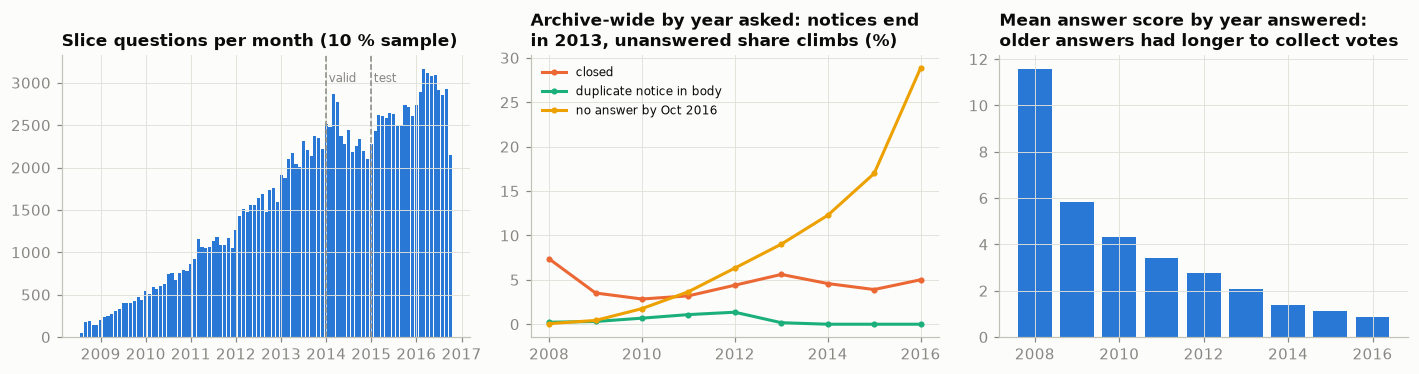

In [3]:
yr = QALL.created.dt.year
in_slice = QALL.id.isin(set(Q.id))
by_year = pd.DataFrame({
    "questions (archive)": QALL.groupby(yr).size(),
    "in the slice": in_slice.groupby(yr).sum(),
    "closed": QALL.closed.notna().groupby(yr).mean(),
    "duplicate notice in body": QALL.dup_notice.groupby(yr).mean(),
    "no answer by Oct 2016": (QALL.n_answers == 0).groupby(yr).mean(),
})
by_year["mean score of slice answers"] = A.groupby(A.created.dt.year).score.mean()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
ax = axes[0]
monthly = Q.groupby(Q.created.dt.to_period("M")).size()
ax.bar(monthly.index.to_timestamp(), monthly.values, width=25, color=SERIES[0])
for x, lab in [(VALID_START, "valid"), (TEST_START, "test")]:
    ax.axvline(x, color=MUTED, ls="--", lw=1); ax.text(x + pd.Timedelta(days=20), monthly.max() * 0.95, lab, color=MUTED, fontsize=8)
ax.set_title("Slice questions per month (10 % sample)")
ax = axes[1]
for col, color in zip(["closed", "duplicate notice in body", "no answer by Oct 2016"], SERIES[1:]):
    ax.plot(by_year.index, by_year[col] * 100, "-o", ms=3, lw=2, color=color, label=col)
ax.set_title("Archive-wide by year asked: notices end\nin 2013, unanswered share climbs (%)"); ax.legend(fontsize=8)
ax = axes[2]
ax.bar(by_year.index, by_year["mean score of slice answers"], color=SERIES[0])
ax.set_title("Mean answer score by year answered:\nolder answers had longer to collect votes")
plt.tight_layout()

first_ans = A.groupby("parent").created.min()
summary = pd.Series({
    "questions": len(Q), "answers": len(A), "answers per question": len(A) / len(Q),
    "questions with ≥ 1 answer": Q.id.isin(A.parent).mean(),
    "median hours to first answer": ((first_ans - Q.set_index("id").created.reindex(first_ans.index)).dt.total_seconds() / 3600).median(),
    "questions with a code block": (Q.code.str.len() > 0).mean(),
    "questions closed": Q.closed.notna().mean(), "questions with a duplicate notice": (Q.dup_notice != "").mean(),
    "answers whose author account is gone": A.owner_id.isna().mean(), "answers linking another question": (A.links.map(len) > 0).mean(),
})
print(summary.round(3).to_string())
by_year.style.format({"questions (archive)": "{:,}", "in the slice": "{:,}", "closed": "{:.1%}", "duplicate notice in body": "{:.2%}",
                      "no answer by Oct 2016": "{:.1%}", "mean score of slice answers": "{:.2f}"})

89 % of slice questions have an answer, the first typically within a quarter of an hour. Three facts shape what follows: **duplicate notices stop after 2013** (1.35 % of 2012's questions, none from 2014); **the unanswered share climbs to 29 % for 2016**, as the snapshot catches questions before anyone answers; and **mean answer score falls every year** (11.6 for 2008's answers, 0.86 for 2016's).

# Part B — The given model

*Sections 3–6: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 3 · Tag prediction, forward in time

*Part B · Given model · package `fit_tagger`, `predict_sets` and `choose_threshold` unchanged; reproduce micro-F1 0.750 (C2).*

Tags route a question to its experts and, in Section 6, steer the retriever. The model is deliberately classical: TF-IDF over counts shared with the retriever (vocabulary and IDF from the index as of 1 January 2015), one logistic regression per tag, 30 tags. Metrics: **micro-F1** at a threshold chosen on validation, and **precision@k** for a ranked routing list.

In [4]:
t0 = time.time()
tr = (Q.created < VALID_START).values
va = ((Q.created >= VALID_START) & (Q.created < TEST_START)).values
te = (Q.created >= TEST_START).values
pre = tr | va                                             # the index snapshot on 1 Jan 2015: vocabulary and IDF are fitted here only

# one tokenisation, shared by the tag model (TF-IDF) and the retriever (BM25, Section 4)
cv = CountVectorizer(stop_words="english", min_df=3, max_features=MAX_FEATURES, dtype=np.float32)
prose = (Q.title + " " + Q.text).values
order = np.r_[np.flatnonzero(pre), np.flatnonzero(~pre)]
C_prose = sp.vstack([cv.fit_transform(prose[pre]), cv.transform(prose[~pre])]).tocsr()[np.argsort(order)]
C_code = cv.transform(Q.code.values)
C = (C_prose + C_code).tocsr()
VOCAB = np.array(cv.get_feature_names_out()); cv.stop_words_ = None   # the pruned-term set is large and never used
bm25_check_docs = prose[np.flatnonzero(pre)[:2_000]].tolist()   # kept for the BM25 test in Section 4
Q = Q.drop(columns=["text", "code"]); del prose, C_code          # the matrices are all we need from here on
print(f"vocabulary {len(VOCAB):,} terms · {C.nnz/len(Q):.0f} distinct terms per thread · tokenised in {time.time()-t0:.0f}s")

# labels: the N_TAGS most frequent tags before VALID_START
rows = pd.Index(Q.id).get_indexer(thread_tags.id)
LABELS = thread_tags.tag[tr[rows]].value_counts().index[:N_TAGS].tolist()
lab = pd.Index(LABELS).get_indexer(thread_tags.tag); keep = lab >= 0
Y = sp.csr_matrix((np.ones(keep.sum(), np.int8), (rows[keep], lab[keep])), shape=(len(Q), N_TAGS)).toarray()
print(f"label vocabulary covers {keep.mean():.0%} of tag assignments; {(Y.sum(1) > 0).mean():.1%} of questions have ≥ 1 label; "
      f"{Y[te].sum(1).mean():.2f} labels per test question")

def fit_tagger(X, Ytr):
    return OneVsRestClassifier(SGDClassifier(loss="log_loss", alpha=2e-6, max_iter=5, tol=None, random_state=SEED), n_jobs=N_JOBS).fit(X, Ytr)

def predict_sets(scores, thr):
    P = (scores >= thr).astype(np.int8); P[np.arange(len(P)), scores.argmax(1)] = 1     # always at least one tag
    return P

def tag_metrics(scores, Yt, thr):
    top = np.argsort(-scores, 1)
    return {"micro-F1": f1_score(Yt, predict_sets(scores, thr), average="micro"),
            "precision@1": np.take_along_axis(Yt, top[:, :1], 1).mean(),
            "precision@3": np.take_along_axis(Yt, top[:, :3], 1).mean(),
            "recall@3": np.take_along_axis(Yt, top[:, :3], 1).sum() / max(Yt.sum(), 1)}

def choose_threshold(scores, Yt):
    grid = np.quantile(scores, np.linspace(0.85, 0.995, 30))
    return grid[int(np.argmax([f1_score(Yt, predict_sets(scores, g), average="micro") for g in grid]))]

t0 = time.time()
tfidf = TfidfTransformer(sublinear_tf=True).fit(C[tr])
X = tfidf.transform(C)
tagger = fit_tagger(X[tr], Y[tr])
S_tag = tagger.decision_function(X).astype(np.float32)      # every thread, for Sections 4, 6 and 7
del X; gc.collect()
THR_TAG = choose_threshold(S_tag[va], Y[va])
tag_res = pd.DataFrame({"validation (2014)": tag_metrics(S_tag[va], Y[va], THR_TAG),
                        "test (2015 – Oct 2016)": tag_metrics(S_tag[te], Y[te], THR_TAG)}).T
print(f"one-vs-rest logistic (SGD) over {N_TAGS} tags · fitted in {time.time()-t0:.0f}s · threshold {THR_TAG:.2f} chosen on validation")
tag_res.style.format("{:.3f}")

vocabulary 26,204 terms · 43 distinct terms per thread · tokenised in 17s
label vocabulary covers 54% of tag assignments; 99.5% of questions have ≥ 1 label; 1.62 labels per test question


one-vs-rest logistic (SGD) over 30 tags · fitted in 9s · threshold -0.50 chosen on validation


,micro-F1,precision@1,precision@3,recall@3
validation (2014),0.753,0.880,0.489,0.854
test (2015 – Oct 2016),0.750,0.862,0.462,0.856


Micro-F1 is 0.75 on validation and test; the top tag is right 86 % of the time on test. The weak spot is coverage: the 30 labels hold 54 % of tag assignments. Trap 1 shows what this steady average hides.

## 4 · Retrieval without an LLM: BM25 over earlier threads, an answer with its attribution

*Part B · Given model · package `bm25_weights`, `search`, `pick_answer`, `attribution` and `ask`; C1 makes the attribution contract a test.*

Nobody marked which earlier thread answers a question, so the golden set comes from links people wrote:

- **linked by an answerer**: an answer links an earlier thread, the answerer's judgement that it is relevant;
- **cited by the asker**: the question links an earlier thread ("I tried this, but…"), related but rarely the whole answer;
- **closed as duplicate**: the 2010–2013 notice names the earlier question; the strongest judgement, but only 45 pairs.

Each is a lower bound: an unlinked thread may still answer. The query is the question re-cleaned from its HTML, without links to other questions (Trap 2).

In [5]:
ids = pd.Index(Q.id)
created_of = Q.set_index("id").created
def pairs(df, family):
    df = df.dropna().astype({"q": "int64", "t": "int64"})
    df = df[df.t.isin(ids) & df.q.isin(ids) & (df.t != df.q)]
    df = df[created_of.reindex(df.t).values < created_of.reindex(df.q).values]
    return df.groupby("q").t.agg(lambda s: frozenset(s)).rename("relevant").reset_index().assign(family=family)

gold = pd.concat([
    pairs(Q[["id", "dup_targets"]].explode("dup_targets").rename(columns={"id": "q", "dup_targets": "t"}), "closed as duplicate"),
    pairs(A[["parent", "links"]].explode("links").rename(columns={"parent": "q", "links": "t"}), "linked by an answerer"),
    pairs(LINKS.loc[LINKS.kind == "question_body", ["source", "target"]].rename(columns={"source": "q", "target": "t"}), "cited by the asker"),
], ignore_index=True)
gold["created"] = created_of.reindex(gold.q).values
gold["split"] = np.select([gold.created < VALID_START, gold.created < TEST_START], ["before 2014", "validation"], "test")

# the query is what the engineer typed: the question re-cleaned from its HTML with every link to another question removed
want = set(gold.q)
html_q = pd.concat([b.to_pandas() for b in pq.ParquetFile(PROCESSED / "28_questions.parquet").iter_batches(columns=["id", "body_html"], batch_size=10_000)
                    for b in [b.filter(pc.is_in(b["id"], pa.array(sorted(want), pa.int32())))]]).set_index("id").body_html
SO_ANCHOR = re.compile(r"<a [^>]*(?:stackoverflow\.com/(?:questions|q|a)/|href=\"/questions/)[^>]*>.*?</a>|https?://(?:www\.)?stackoverflow\.com/\S+", re.S)
def query_text(qid, keep_links=False, raw_html=False):
    body = html_q[qid]
    if raw_html:
        return Q.title.values[ids.get_loc(qid)] + " " + body                  # the naive pipeline: HTML, notice and links included
    _, _, prose_, code_, *_ = clean(body if keep_links else SO_ANCHOR.sub(" ", body))
    return Q.title.values[ids.get_loc(qid)] + " " + prose_[:1_500], code_[:600]
gold_tbl = gold.pivot_table(index="family", columns="split", values="q", aggfunc="count", fill_value=0)[["before 2014", "validation", "test"]]
gold_tbl["relevant threads per query"] = gold.groupby("family").relevant.apply(lambda s: s.map(len).mean())
print(f"golden set: {len(gold):,} (query, family) rows over {gold.q.nunique():,} distinct questions")
gold_tbl.style.format({"relevant threads per query": "{:.2f}"})

golden set: 1,100 (query, family) rows over 1,081 distinct questions


split,before 2014,validation,test,relevant threads per query
family,,,,
cited by the asker,168,65,195,1.03
closed as duplicate,45,0,0,1.00
linked by an answerer,323,93,211,1.01


`rank_bm25` (notebook 04) loops in Python over every document; here the same formula runs as sparse algebra, checked against it first.

In [6]:
# BM25 over the shared count matrix, as sparse algebra: the same scores as rank_bm25, in milliseconds instead of minutes
N_pre = int(pre.sum())
df_ = np.bincount(C[pre].indices, minlength=C.shape[1])
idf = np.log(N_pre - df_ + 0.5) - np.log(df_ + 0.5)
idf = np.where(idf < 0, 0.25 * idf.mean(), idf).astype(np.float32)        # rank_bm25's floor for very common terms

def bm25_weights(Cm, k1=BM25_K1, b=BM25_B, avgdl=None):
    Cm = Cm.tocsr().astype(np.float32, copy=True)
    dl = np.asarray(Cm.sum(1)).ravel(); avgdl = avgdl or dl[pre].mean()
    rows_ = np.repeat(np.arange(Cm.shape[0]), np.diff(Cm.indptr))
    Cm.data = Cm.data * (k1 + 1) / (Cm.data + k1 * (1 - b + b * dl[rows_] / avgdl))
    return (Cm @ sp.diags(idf)).tocsr()

W_title = bm25_weights(cv.transform(Q.title.values))
W = {"title + text": bm25_weights(C_prose),
     "title + text + code": bm25_weights(C)}

# a test that the sparse version is BM25: compare with rank_bm25 on 2,000 threads (own IDF and length statistics)
from rank_bm25 import BM25Okapi
an = cv.build_analyzer(); vset = set(VOCAB)
small = np.flatnonzero(pre)[:2_000]
toks = [[w for w in an(d) if w in vset] for d in bm25_check_docs]
ref = BM25Okapi(toks, k1=BM25_K1, b=BM25_B)
idf_keep = idf.copy()
df_s = np.bincount(C_prose[small].indices, minlength=C.shape[1])
idf_s = np.log(len(small) - df_s + 0.5) - np.log(df_s + 0.5)
idf = np.where(df_s > 0, np.where(idf_s < 0, ref.epsilon * ref.average_idf, idf_s), 0).astype(np.float32)
Cs = C_prose[small]; Ws = bm25_weights(Cs, avgdl=np.asarray(Cs.sum(1)).ravel().mean())
idf = idf_keep
qtok = toks[7][:12]
mine = (Ws @ cv.transform([" ".join(qtok)]).T).toarray().ravel()
assert np.allclose(mine, ref.get_scores(qtok), rtol=1e-4, atol=1e-4), "sparse BM25 disagrees with rank_bm25"
print(f"sparse BM25 matches rank_bm25 on {len(small):,} threads (max abs diff {np.abs(mine - ref.get_scores(qtok)).max():.1e})")

sparse BM25 matches rank_bm25 on 2,000 threads (max abs diff 1.8e-06)


Three indexes, scored on validation (2014) and test (2015–16) for the two families with enough queries. A query sees only threads created before it (the as-of rule).

In [7]:
# queries, the as-of rule, and the scoreboard
q_rows = ids.get_indexer(gold.q)
q_time = gold.created.values.astype("datetime64[s]").astype(np.int64)
doc_time = Q.created.values.astype("datetime64[s]").astype(np.int64)
SEC_PER_YEAR = 365.25 * 86400

def query_matrix(texts):
    return (cv.transform([t for t, _ in texts]) + cv.transform([c for _, c in texts])).tocsr()
QV = query_matrix([query_text(q) for q in gold.q])
W["title ×2 + text + code"] = (2 * W_title + W["title + text + code"]).tocsr(); del W_title

def search(Wm, QVm, sel, depth=100, as_of=True):
    """Top-`depth` threads per selected query, with BM25 scores; only threads created before the query exist (the as-of rule)."""
    rows_ = np.flatnonzero(sel)
    cand = np.full((len(gold), depth), -1, np.int32); csc = np.full((len(gold), depth), -np.inf, np.float32)
    for s0 in range(0, len(rows_), 64):
        b = rows_[s0:s0 + 64]
        S = (Wm @ QVm[b].T).toarray()
        for j, i in enumerate(b):
            sc = np.where((doc_time < q_time[i]) if as_of else (q_rows[i] != np.arange(len(doc_time))), S[:, j], -np.inf)
            top = np.argpartition(-sc, depth)[:depth]; top = top[np.argsort(-sc[top])]
            cand[i], csc[i] = top, sc[top]
    return cand, csc

REL = gold.relevant.values
REL_ROWS = [ids.get_indexer(sorted(r)) for r in REL]
def first_hit(cand, sel=None):
    """Rank (1-based) of the first relevant thread per query; inf when it is not in the list."""
    out = np.full(len(gold), np.inf)
    for i in (np.flatnonzero(sel) if sel is not None else range(len(gold))):
        h = np.flatnonzero(np.isin(cand[i], REL_ROWS[i]))
        if len(h):
            out[i] = h[0] + 1
    return out

def scores_of(first, sel):
    f = first[sel]
    return {"recall@1": (f <= 1).mean(), f"recall@{K}": (f <= K).mean(), "recall@20": (f <= 20).mean(), "MRR": (1 / f).mean(), "n": int(sel.sum())}

evaluated = (gold.split != "before 2014").values
t0 = time.time()
board = {}
for name, Wm in W.items():
    first = first_hit(search(Wm, QV, evaluated)[0], evaluated)
    for split in ["validation", "test"]:
        for fam in ["linked by an answerer", "cited by the asker"]:
            board[(name, split, fam)] = scores_of(first, ((gold.split == split) & (gold.family == fam)).values)
board = pd.DataFrame(board).T.rename_axis(["index", "split", "family"])
pooled = board.xs("validation", level="split").assign(hits=lambda d: d[f"recall@{K}"] * d.n, rr=lambda d: d.MRR * d.n).groupby("index")[["hits", "rr", "n"]].sum()
INDEX = (pooled.hits / pooled.n).round(3).to_frame("r").assign(m=pooled.rr / pooled.n).sort_values(["r", "m"], ascending=False).index[0]
print(f"{len(W)} indexes × {evaluated.sum():,} queries ranked in {time.time()-t0:.0f}s · chosen on validation (pooled recall@{K}, then MRR): {INDEX}")
board.style.format({"recall@1": "{:.2f}", f"recall@{K}": "{:.2f}", "recall@20": "{:.2f}", "MRR": "{:.3f}", "n": "{:.0f}"})

3 indexes × 564 queries ranked in 16s · chosen on validation (pooled recall@5, then MRR): title ×2 + text + code


Doubling the title's weight wins on validation, and test agrees; still, the linked thread reaches the top five for only 12 % of answerer-linked test questions and 37 % of asker-cited ones. The given retriever is weak (say so in the model card), and an answerer's link says "related", not "this answers it".

### The reader: one answer per thread, cited, and only what existed then

The reader takes each suggested thread's top-voted answer **among those posted before the question** and attaches what CC BY-SA 3.0 (Section 4) and Stack Overflow's attribution guidance ask for, as far as this data allows: answer and thread links, the author's profile link built from the owner ID, and the licence with its URI. An answer from a deleted account has no one to credit, so it is not shown.

In [8]:
# the reader: for each suggested thread, the answer to show (as of the query) and its attribution
CAND, CSC = search(W[INDEX], QV, np.ones(len(gold), bool), depth=1_000)   # candidate pool for Sections 5 and 6
A_s = A.sort_values(["parent", "created"]).reset_index(drop=True)
a_lo = np.searchsorted(A_s.parent.values, Q.id.values, "left"); a_hi = np.searchsorted(A_s.parent.values, Q.id.values, "right")
a_time = A_s.created.values.astype("datetime64[s]").astype(np.int64)
a_score, a_stale, a_owner = A_s.score.values, A_s.stale_api.values, A_s.owner_id.notna().values
LICENCE = ("CC BY-SA 3.0", "https://creativecommons.org/licenses/by-sa/3.0/")

def pick_answer(row, t_query, policy="top-voted", attributable_only=True):
    """Index into A_s of the answer to show for thread `row`, using only answers that existed at `t_query`; -1 if none."""
    sl = np.arange(a_lo[row], a_hi[row]); sl = sl[a_time[sl] < t_query]
    if attributable_only:                                   # no owner ID (deleted account) → no author to credit → not shown
        sl = sl[a_owner[sl]]
    if len(sl) == 0:
        return -1
    if policy == "fresh-first" and (~a_stale[sl]).any():   # Section 6: prefer answers that use no removed API
        sl = sl[~a_stale[sl]]
    return sl[np.argmax(a_score[sl])]                       # top-voted; ties go to the earliest (sl is in time order)

def attribution(ai):
    r = A_s.iloc[ai]
    return {"source": "Stack Overflow", "answer": f"https://stackoverflow.com/a/{r.id}", "thread": f"https://stackoverflow.com/q/{r.parent}",
            "author_profile": f"https://stackoverflow.com/users/{int(r.owner_id)}" if pd.notna(r.owner_id) else None,
            "author_name": None,          # display names are not in StackSample; a production copilot fetches them at render time
            "licence": LICENCE[0], "licence_url": LICENCE[1], "posted": f"{r.created:%Y-%m-%d}", "score": int(r.score)}

def ask(i, k=3, policy="top-voted", cand=None, attributable_only=True):
    """What the copilot returns for golden query i: up to k earlier threads with an answer it can show and credit."""
    cand = CAND if cand is None else cand
    out = []
    for d in cand[i]:
        if d < 0 or len(out) == k:
            break
        ai = pick_answer(d, q_time[i], policy, attributable_only)
        if ai >= 0:
            out.append({"thread_row": int(d), "answer_row": int(ai), **attribution(ai)})
    return out

test_q = np.flatnonzero((gold.split == "test").values)
shown = [a for i in test_q for a in ask(i, k=3)]
loose = [a for i in test_q for a in ask(i, k=3, attributable_only=False)]
cite = pd.DataFrame(shown)
attr = pd.Series({"answers shown (test, top 3)": len(cite),
                  "post links (answer and thread)": cite[["answer", "thread"]].notna().all(1).mean(),
                  "author profile link, built from the owner ID": cite.author_profile.notna().mean(),
                  "licence named, with its URI": ((cite.licence == LICENCE[0]) & (cite.licence_url == LICENCE[1])).mean(),
                  "author display name": cite.author_name.notna().mean()})
print(attr.to_string(float_format=lambda v: f"{v:.1%}" if v <= 1 else f"{v:,.0f}"))
print(f"without the author rule {np.mean([a['author_profile'] is None for a in loose]):.1%} of shown answers would have no author to credit "
      f"(deleted accounts; {(~a_owner).mean():.1%} of the slice's answers)")
# the contract a CI test enforces: every shown answer links the post and the author's profile and names the licence with its URI
assert all(a["answer"] and a["thread"] and a["author_profile"] and a["licence"] == LICENCE[0] and a["licence_url"] == LICENCE[1] for a in shown), \
    "an answer is shown without its attribution"

# one worked example: a test question whose answerer pointed to an earlier thread, and what the copilot shows
first_tbl = first_hit(CAND)
ex = next(i for i in test_q if first_tbl[i] == 1 and gold.family.values[i] == "linked by an answerer")
print(f"\nquestion ({pd.Timestamp(gold.created.values[ex]):%Y-%m-%d}): {Q.title.values[q_rows[ex]]}")
for r_, a in enumerate(ask(ex, k=3), 1):
    rel = "  ← the thread the answerer linked" if ids[a["thread_row"]] in REL[ex] else ""
    print(f"  {r_}. {Q.title.values[a['thread_row']][:80]}{rel}\n     answer {a['answer']} · score {a['score']} · posted {a['posted']} · "
          f"author {a['author_profile']} · {a['licence']} ({a['licence_url']})")
print(f"  top answer begins: “{A_s.snippet.values[ask(ex, k=1)[0]['answer_row']][:160]}…”")

answers shown (test, top 3)                     1,218
post links (answer and thread)                 100.0%
author profile link, built from the owner ID   100.0%
licence named, with its URI                    100.0%
author display name                              0.0%
without the author rule 0.7% of shown answers would have no author to credit (deleted accounts; 0.6% of the slice's answers)

question (2015-02-04): Eval scope in a function
  1. scope of eval function in python  ← the thread the answerer linked
     answer https://stackoverflow.com/a/27379749 · score 13 · posted 2014-12-09 · author https://stackoverflow.com/users/846892 · CC BY-SA 3.0 (https://creativecommons.org/licenses/by-sa/3.0/)
  2. How is the second argument of the eval function different from the third argumen
     answer https://stackoverflow.com/a/4048844 · score 3 · posted 2010-10-29 · author https://stackoverflow.com/users/20862 · CC BY-SA 3.0 (https://creativecommons.org/licenses/by-sa/3.0/)
  3. Python Eva

Every shown answer carries the post links, the author's profile link and the licence with its URI; the `assert` is the contract a CI test enforces. Without the author rule, 0.7 % of shown answers would credit no one. The contract is still **partial**: the guidance also asks for each author's display name, linked to the profile. StackSample has no names (0 % above), so this notebook cannot show them; a production copilot fetches them when it renders an answer (task C1). The example's first suggestion is the thread the answerer linked.

## 5 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test.*

**Trap 1 — the random split, and an average that hides decay.** The same tagger, trained and tested on shuffled rows of the same sizes.

In [9]:
# Trap 1: the same tag model, trained and tested on a random split of the same sizes
perm = rng.permutation(len(Q))
n_tr, n_va, n_te = int(tr.sum()), int(va.sum()), int(te.sum())
r_tr, r_va, r_te = perm[:n_tr], perm[n_tr:n_tr + n_va], perm[n_tr + n_va:n_tr + n_va + n_te]
tfidf_r = TfidfTransformer(sublinear_tf=True).fit(C[r_tr])
Xr = tfidf_r.transform(C)
tagger_r = fit_tagger(Xr[r_tr], Y[r_tr])
S_r = tagger_r.decision_function(Xr).astype(np.float32)
thr_r = choose_threshold(S_r[r_va], Y[r_va])
split_tbl = pd.DataFrame({"random split (all years mixed)": tag_metrics(S_r[r_te], Y[r_te], thr_r),
                          "forward split (train ≤ 2013, test 2015–16)": tag_metrics(S_tag[te], Y[te], THR_TAG)}).T
VERSIONED = [t for t in LABELS if re.search(r"-(\d|x)", t)]
per_tag = pd.DataFrame({"random": f1_score(Y[r_te], predict_sets(S_r[r_te], thr_r), average=None),
                        "forward": f1_score(Y[te], predict_sets(S_tag[te], THR_TAG), average=None)}, index=LABELS)
display(split_tbl.style.format("{:.3f}"))
print("F1 on the versioned tags:", {t: f"{per_tag.loc[t, 'random']:.2f} → {per_tag.loc[t, 'forward']:.2f}" for t in VERSIONED})
TOP3 = LABELS[:3]
print(f"the three largest labels {TOP3} hold {Y[te][:, :3].sum() / Y[te].sum():.0%} of test label assignments; F1 random → forward:",
      {t: f"{per_tag.loc[t, 'random']:.2f} → {per_tag.loc[t, 'forward']:.2f}" for t in TOP3})
del Xr, tfidf_r; _ = gc.collect()

,micro-F1,precision@1,precision@3,recall@3
random split (all years mixed),0.744,0.866,0.473,0.850
"forward split (train ≤ 2013, test 2015–16)",0.750,0.862,0.462,0.856


F1 on the versioned tags: {'sql-server-2008': '0.27 → 0.23', 'sql-server-2005': '0.34 → 0.24', 'python-2.7': '0.07 → 0.03', 'python-3.x': '0.15 → 0.11'}
the three largest labels ['python', 'mysql', 'sql'] hold 54% of test label assignments; F1 random → forward: {'python': '0.95 → 0.94', 'mysql': '0.88 → 0.87', 'sql': '0.64 → 0.63'}


The random split is *not* more flattering here (micro-F1 0.744 against 0.750): the three largest labels (`python`, `mysql`, `sql`) hold 54 % of test labels and keep their F1 (0.95 → 0.94, 0.88 → 0.87, 0.64 → 0.63). Forward, every versioned tag loses F1 (`sql-server-2005` 0.34 → 0.24, `python-2.7` 0.07 → 0.03), which a micro-F1 gate would never notice (task C1). Retrieval's version of this trap is the as-of rule, below.

**Trap 2 — HTML, links and code in the text.** The raw body, then the cleaned body with links kept, then the honest query.

In [10]:
# Trap 2: HTML, links and code in the text — the same retriever, fed what a naive pipeline would feed it
sel_dup = (gold.family == "closed as duplicate").values
sel_t = (gold.split == "test").values
variants = {
    "raw HTML body (notice, links, markup)": query_matrix([(query_text(q, raw_html=True), "") for q in gold.q]),
    "cleaned, links to other questions kept": query_matrix([query_text(q, keep_links=True) for q in gold.q]),
    "cleaned, links removed (honest)": QV,
}
trap2 = {}
for name, QVm in variants.items():
    f = first_hit(search(W[INDEX], QVm, sel_dup | sel_t)[0], sel_dup | sel_t)
    trap2[(name, "closed as duplicate (2010–12)")] = scores_of(f, sel_dup)
    for fam in ["cited by the asker", "linked by an answerer"]:
        trap2[(name, fam + " (test)")] = scores_of(f, sel_t & (gold.family == fam).values)
f_noasof = first_hit(search(W[INDEX], QV, sel_t, as_of=False)[0], sel_t)
trap2 = pd.DataFrame(trap2).T[["recall@1", f"recall@{K}", "MRR", "n"]]
display(trap2.style.format({"recall@1": "{:.2f}", f"recall@{K}": "{:.2f}", "MRR": "{:.3f}", "n": "{:.0f}"}))
code_gain = board.loc[("title + text + code", "test"), f"recall@{K}"] - board.loc[("title + text", "test"), f"recall@{K}"]
print(f"code blocks in the index: recall@{K} on test {board.loc[('title + text', 'test'), f'recall@{K}'].round(2).to_dict()} → "
      f"{board.loc[('title + text + code', 'test'), f'recall@{K}'].round(2).to_dict()}")
dump_top = [A_s.score.values[a_lo[d]:a_hi[d]].argmax() + a_lo[d] for d in [a["thread_row"] for i in test_q for a in ask(i, k=1)]]
future = np.mean([a_time[ai] > q_time[i] for i, ai in zip([i for i in test_q if ask(i, k=1)], dump_top)])
print(f"showing the dump's top-voted answer instead of the top answer at the time of asking: {future:.1%} of test questions would be shown an answer posted after they were asked")
print(f"ignoring the as-of rule (index holds later threads too): recall@{K} on test {scores_of(f_noasof, sel_t)[f'recall@{K}']:.3f} vs "
      f"{scores_of(first_hit(CAND), sel_t)[f'recall@{K}']:.3f} with it")

code blocks in the index: recall@5 on test {'linked by an answerer': 0.1, 'cited by the asker': 0.26} → {'linked by an answerer': 0.1, 'cited by the asker': 0.34}
showing the dump's top-voted answer instead of the top answer at the time of asking: 0.2% of test questions would be shown an answer posted after they were asked


ignoring the as-of rule (index holds later threads too): recall@5 on test 0.222 vs 0.241 with it


The duplicate notice nearly doubles recall@5 for closed duplicates (0.42 → 0.82; recall@1 0.27 → 0.60): the notice *is* the earlier title. The asker's links do the same (0.37 → 0.51 kept, 0.60 raw). Neither is retrieval. Code blocks are genuine signal, worth 8 points on asker-cited questions. Without the as-of rule, later threads compete (recall@5 0.241 → 0.222) and 0.2 % of questions would see an answer posted after them.

**Trap 3 — answers go out of date.** Three API families since removed, detected in answers' code (dates in the load cell): PHP's `mysql_*`, Python 2 syntax and pandas `.ix`.

top answers shown on 406 test questions: median age 1.7 years; 9.1% use an API removed by today, 1.0% one already deprecated when asked


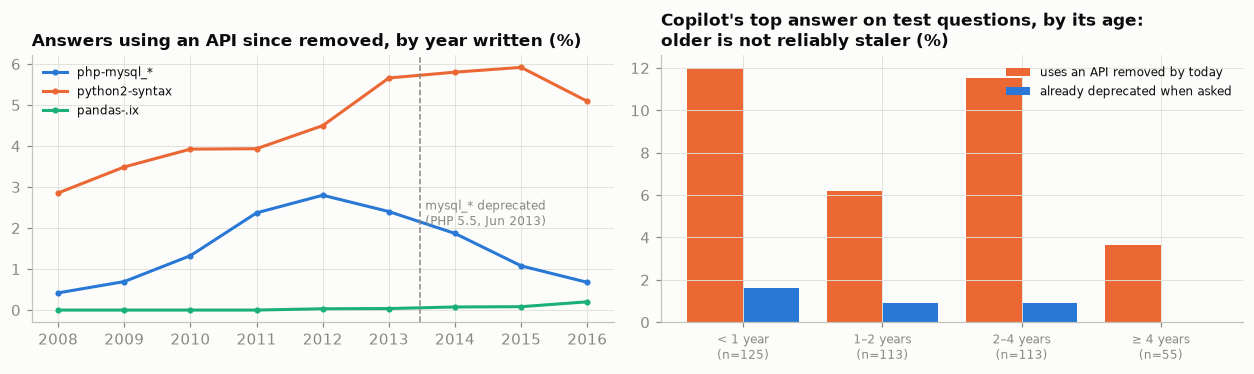

In [11]:
# Trap 3: answers go out of date — by the year they were written, and in what the copilot shows
mk = list(STALE_API.marker)
stale_by_year = A.groupby(A.created.dt.year)[mk].mean() * 100
top1 = pd.DataFrame([{"i": i, **a[0]} for i in test_q for a in [ask(i, k=1)] if a])
top1["age_years"] = (q_time[top1.i] - a_time[top1.answer_row]) / SEC_PER_YEAR
top1["stale today"] = a_stale[top1.answer_row]
stale_from = dict(zip(STALE_API.marker, STALE_API.stale_from.values.astype("datetime64[s]").astype(np.int64)))
top1["stale when asked"] = np.any([A_s[m].values[top1.answer_row] & (stale_from[m] <= q_time[top1.i]) for m in mk], axis=0)
top1["age band"] = pd.cut(top1.age_years, [0, 1, 2, 4, 9], labels=["< 1 year", "1–2 years", "2–4 years", "≥ 4 years"], right=False)
by_age = top1.groupby("age band", observed=False).agg(shown=("i", "size"), stale_today=("stale today", "mean"), stale_when_asked=("stale when asked", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.5))
ax = axes[0]
for m, color in zip(mk, SERIES):
    ax.plot(stale_by_year.index, stale_by_year[m], "-o", ms=3, lw=2, color=color, label=m)
ax.axvline(2013.47, color=MUTED, ls="--", lw=1); ax.text(2013.55, stale_by_year.values.max() * 0.35, "mysql_* deprecated\n(PHP 5.5, Jun 2013)", color=MUTED, fontsize=8)
ax.set_title("Answers using an API since removed, by year written (%)"); ax.legend(fontsize=8, loc="upper left")
ax = axes[1]
xb = np.arange(len(by_age))
ax.bar(xb - 0.2, by_age.stale_today * 100, width=0.4, color=SERIES[1], label="uses an API removed by today")
ax.bar(xb + 0.2, by_age.stale_when_asked * 100, width=0.4, color=SERIES[0], label="already deprecated when asked")
ax.set_xticks(xb); ax.set_xticklabels([f"{b}\n(n={n})" for b, n in zip(by_age.index, by_age.shown)], fontsize=8)
ax.set_title("Copilot's top answer on test questions, by its age:\nolder is not reliably staler (%)"); ax.legend(fontsize=8)
plt.tight_layout()
print(f"top answers shown on {len(top1)} test questions: median age {top1.age_years.median():.1f} years; "
      f"{top1['stale today'].mean():.1%} use an API removed by today, {top1['stale when asked'].mean():.1%} one already deprecated when asked")

6.9 % of the slice's answers use one. Python 2 syntax rises until 2015; `mysql_*` peaks in 2012 and falls after its 2013 deprecation, never to zero. The copilot's top answer on test questions is a median 1.7 years old, and 9.1 % use an API removed by today (1.0 % one deprecated when asked). Older answers are not reliably staler (right panel): the API called is the signal, not age.

**Trap 4 — accepted is not correct, and top-voted is not current.** With no accepted flag, the substitute is the top-voted answer.

In [12]:
# Trap 4: no accepted flag, and the top-voted answer is not the current one
g = A_s.assign(pos=A_s.groupby("parent").cumcount())
n_ans = g.groupby("parent").size()
top_pos = g.loc[g.groupby("parent").score.idxmax(), ["parent", "pos", "stale_api"]].set_index("parent")
multi = n_ans[n_ans >= 2].index
mixed = g.groupby("parent").stale_api.agg(["any", "all"]).query("`any` and not `all`").index
print(f"threads with ≥ 2 answers: {len(multi):,}; the top-voted answer is the first one posted in {(top_pos.loc[multi, 'pos'] == 0).mean():.0%}")
print(f"threads with one answer using a removed API and one that does not: {len(mixed):,}; the top-voted answer is the removed-API one in "
      f"{top_pos.loc[mixed, 'stale_api'].mean():.0%}")
fresh = [ask(i, k=1, policy="fresh-first") for i in test_q]
print(f"stale share of the copilot's top answer on test questions · top-voted reader {a_stale[top1.answer_row].mean():.1%} · "
      f"fresh-first reader {np.mean([a_stale[a[0]['answer_row']] for a in fresh if a]):.1%} (same threads, same recall)")

threads with ≥ 2 answers: 68,557; the top-voted answer is the first one posted in 64%
threads with one answer using a removed API and one that does not: 8,689; the top-voted answer is the removed-API one in 43%
stale share of the copilot's top answer on test questions · top-voted reader 9.1% · fresh-first reader 5.7% (same threads, same recall)


In 64 % of multi-answer threads the top-voted answer is simply the first one posted; where one answer uses a removed API and another does not, the removed-API answer is top-voted in 43 %. Votes record what helped then. Preferring answers that use no removed API cuts stale top answers from 9.1 % to 5.7 %, with the same threads found.

**Trap 5 — closed threads, duplicates and dead ends.**

In [13]:
# Trap 5: closed threads and threads with nothing to show
closed_t = Q.closed.values.astype("datetime64[s]").astype(np.int64)        # NaT → very negative; masked below
closed_known = Q.closed.notna().values
first_ans_t = A_s.groupby("parent").created.min().reindex(Q.id).values.astype("datetime64[s]").astype(np.int64)
answered_known = Q.id.isin(A_s.parent).values
naive = CAND[test_q, :3]
qt3 = q_time[test_q][:, None]
closed_then = closed_known[naive] & (closed_t[naive] < qt3)
no_answer_then = ~answered_known[naive] | (first_ans_t[naive] >= qt3)
fixed_rows = [[a["thread_row"] for a in ask(i, k=3)] for i in test_q]
def hit3(rowlists):
    return np.mean([any(ids[d] in REL[i] for d in rl) for i, rl in zip(test_q, rowlists)])
print(f"naive top-3 on test: {closed_then.mean():.1%} of suggestions already closed, {no_answer_then.mean():.1%} with no answer yet "
      f"(nothing to show); {(no_answer_then.all(1)).mean():.1%} of questions get no answer at all")
def title_words(r):
    return set(re.findall(r"[a-z0-9_]{3,}", Q.title.values[r].lower()))
near_dup = np.mean([any(len(title_words(a) & title_words(b)) / max(len(title_words(a) | title_words(b)), 1) >= 0.6
                        for a, b in [(r[0], r[1]), (r[0], r[2]), (r[1], r[2])]) for r in naive])
print(f"top-3 lists holding two near-identical threads (title word overlap ≥ 60 %): {near_dup:.1%}")
print(f"relevant thread among the top 3 · naive {hit3(naive):.1%} (of which with an answer to show "
      f"{np.mean([any(ids[d] in REL[i] and not na for d, na in zip(r, n)) for i, r, n in zip(test_q, naive, no_answer_then)]):.1%}) · "
      f"answered threads only {hit3(fixed_rows):.1%}")

naive top-3 on test: 4.0% of suggestions already closed, 10.0% with no answer yet (nothing to show); 0.0% of questions get no answer at all
top-3 lists holding two near-identical threads (title word overlap ≥ 60 %): 3.0%
relevant thread among the top 3 · naive 20.0% (of which with an answer to show 19.7%) · answered threads only 20.7%


A naive top three includes threads already closed (4.0 % of suggestions) and threads with no answer yet (10.0 %); 3.0 % of lists hold two near-identical threads. Skipping dead ends costs nothing (relevant thread among three shown answers: 20.0 % → 20.7 %), so `ask()` does it. Collapsing duplicates needs duplicate links (task E3).

## 6 · A knowledge layer, its ablation, and the operating point

*Part B · Given model · package `query_tags`, `rerank` and `minutes_per_question`; E1 redoes the ablation, C3 owns the number of suggestions.*

Three competency questions a copilot needs answered at request time: *which tags travel together?*, *which versions of a library exist, since when?*, *which of its APIs were removed, and when?* The graph is built from the index snapshot (threads before 2015) and versioned like a model.

In [14]:
# the tag co-occurrence graph, built on the index snapshot (threads before TEST_START) — a versioned artefact
tt = thread_tags.assign(row=ids.get_indexer(thread_tags.id))
tt_pre = tt[pre[tt.row.values]]
tag_n = tt_pre.tag.value_counts()
NODES = tag_n[tag_n >= MIN_TAG_THREADS].index
e_ = tt_pre.loc[tt_pre.tag.isin(NODES), ["id", "tag"]]
co = e_.merge(e_, on="id").query("tag_x < tag_y").groupby(["tag_x", "tag_y"]).size().rename("n").reset_index()
co["lift"] = co.n * int(pre.sum()) / (tag_n.reindex(co.tag_x).values * tag_n.reindex(co.tag_y).values)
co = co[(co.n >= 5) & (co.lift >= 2)]
G = nx.Graph()
G.add_nodes_from((t, {"kind": "tag", "threads": int(tag_n[t])}) for t in NODES)
G.add_edges_from((a, b, {"rel": "co_occurs", "n": int(n), "lift": float(l)}) for a, b, n, l in co.itertuples(index=False))

# versioned library entities: `python-3.x` is version `3.x` of library `python`; first seen in the archive, not in a release note
VERSION_RE = re.compile(r"^(?P<lib>[a-z][a-z0-9.+#-]*?)-(?P<ver>\d+(?:\.\d+)*(?:\.x)?(?:-r2)?)$")
vers = pd.DataFrame([{"tag": t, **VERSION_RE.match(t).groupdict()} for t in NODES if VERSION_RE.match(t)])
vers = vers[vers.lib.isin(NODES) | vers.lib.duplicated(keep=False)]   # a library is a tag of its own or has ≥ 2 versions (drops utf-8)
year_of = pd.Series(QALL.created.values, index=QALL.id)
first_seen = TAGS[TAGS.tag.isin(vers.tag)].assign(created=lambda d: year_of.reindex(d.id).values).groupby("tag", observed=True).created.min()
for r in vers.itertuples():
    G.add_node(f"lib:{r.lib}", kind="library")
    G.nodes[r.tag].update(kind="version", version=r.ver, first_seen=str(first_seen.get(r.tag, pd.NaT).date()))
    G.add_edge(r.tag, f"lib:{r.lib}", rel="version_of")
    if r.lib in G:
        G.add_edge(r.lib, f"lib:{r.lib}", rel="same_as")
for r in STALE_API.itertuples():                       # the removed-API facts hang off their library
    G.add_node(f"lib:{r.library}", kind="library")
    G.add_node(f"api:{r.marker}", kind="removed_api", status=r.status, stale_from=str(r.stale_from.date()))
    G.add_edge(f"api:{r.marker}", f"lib:{r.library}", rel="api_of")
kinds = Counter(d["kind"] for _, d in G.nodes(data=True))
print(f"knowledge graph: {G.number_of_nodes():,} nodes {dict(kinds)} · {G.number_of_edges():,} edges")
lib_tbl = (vers.assign(threads=vers.tag.map(tag_n), first_seen=vers.tag.map(first_seen).dt.strftime("%Y-%m"))
           .sort_values(["lib", "first_seen"]).groupby("lib").agg(versions=("ver", lambda v: ", ".join(v)), first_seen=("first_seen", lambda v: f"{v.min()} → {v.max()}"),
                                                                threads=("threads", "sum")).sort_values("threads", ascending=False))
display(lib_tbl.head(8))
nb_ = sorted(((d["n"], n) for n, d in G["pandas"].items() if d.get("rel") == "co_occurs"), reverse=True)[:6]
print("competency question 'what sits next to pandas?':", [n for _, n in nb_])
print("competency question 'when was each version first asked about?':",
      {t: G.nodes[t]["first_seen"] for t in ["python-3.x", "python-3.4", "sql-server-2008", "sql-server-2012"] if t in G})

knowledge graph: 834 nodes {'tag': 781, 'version': 34, 'library': 16, 'removed_api': 3} · 3,194 edges


,versions,first_seen,threads
lib,,,
sql-server,"2008, 2005, 2000, 2008-r2, 2012",2008-08 → 2008-12,7136
python,"2.5, 3.x, 2.x, 2.6, 2.7, 3.3, 3.4",2008-09 → 2013-09,4457
visual-studio,"2008, 2010, 2012, 2013",2008-08 → 2013-06,437
ruby-on-rails,"3, 4, 3.2",2010-02 → 2012-01,327
postgresql,"9.1, 9.2, 9.3",2011-11 → 2013-07,238
ms-access,"2007, 2010",2008-09 → 2010-08,182
asp.net-mvc,"3, 4",2009-02 → 2011-04,125
entity-framework,"4, 5",2009-11 → 2012-03,112


competency question 'what sits next to pandas?': ['python', 'dataframe', 'numpy', 'python-2.7', 'matplotlib', 'csv']
competency question 'when was each version first asked about?': {'python-3.x': '2008-12-04', 'python-3.4': '2013-09-04', 'sql-server-2008': '2008-08-04', 'sql-server-2012': '2008-12-10'}


A warning: a question tagged `sql-server-2012` was asked in December 2008, because tags were edited later. Release dates must come from release notes (task E1).

The KB can act **at retrieval**, boosting threads that share the query's predicted tags (β, optionally graph-expanded) and down-weighting old threads (λ per year), or **at the reader**, preferring answers without a removed API. A component is adopted only if its validation gain's 95 % bootstrap interval excludes zero.

In [15]:
# the ablation: rerank the same BM25 candidates with (a) predicted tags, (b) graph-expanded tags, (c) recency
node_ix = pd.Index(NODES)
col = node_ix.get_indexer(tt.tag); ok = col >= 0
D = sp.csr_matrix((np.ones(int(ok.sum()), np.float32), (tt.row.values[ok], col[ok])), shape=(len(Q), len(NODES)))     # thread × tag
LAB = np.array(LABELS)

S_query = tagger.decision_function(tfidf.transform(QV)).astype(np.float32)   # tags predicted from the honest query (links removed)

def query_tags(i, graph=False, n_pred=3):
    T = set(LAB[np.argsort(-S_query[i])[:n_pred]])
    if graph:
        for t in list(T):
            if t not in G:
                continue
            T |= {n for _, n in sorted(((d["n"], n) for n, d in G[t].items() if d.get("rel") == "co_occurs"), reverse=True)[:2]}
            T |= {n.split(":", 1)[1] for n in G[t] if G[t][n].get("rel") == "version_of" and n.split(":", 1)[1] in G}   # python-3.x → python
    return [t for t in T if t in node_ix]

QT = {g_: np.zeros((len(gold), len(NODES)), np.float32) for g_ in (False, True)}
for g_ in QT:
    for i in range(len(gold)):
        QT[g_][i, node_ix.get_indexer(query_tags(i, graph=g_))] = 1
cand_age = (q_time[:, None] - doc_time[CAND]) / SEC_PER_YEAR

def rerank(beta=0.0, graph=False, lam=0.0, sel=None):
    out = CAND.copy()
    for i in (np.flatnonzero(sel) if sel is not None else range(len(gold))):
        qt_ = QT[graph][i]
        frac = (D[CAND[i]] @ qt_) / max(qt_.sum(), 1) if beta else 0.0
        s_ = CSC[i] * (1 + beta * frac) * np.exp(-lam * cand_age[i])
        out[i] = CAND[i][np.argsort(-s_)]
    return out

val_bc = ((gold.split == "validation") & gold.family.isin(["linked by an answerer", "cited by the asker"])).values
test_bc = ((gold.split == "test") & gold.family.isin(["linked by an answerer", "cited by the asker"])).values
grid = []
for beta in [0.0, 0.25, 0.5, 1.0, 2.0]:
    for graph in [False, True]:
        for lam in [0.0, 0.05, 0.1, 0.2, 0.4]:
            if beta == 0 and graph:
                continue
            f = first_hit(rerank(beta, graph, lam, sel=val_bc), val_bc)
            grid.append({"beta": beta, "graph": graph, "lam": lam, **scores_of(f, val_bc)})
grid = pd.DataFrame(grid)
def best(q):
    return grid.query(q).sort_values([f"recall@{K}", "MRR"], ascending=False).iloc[0]
configs = {"BM25 only": (0.0, False, 0.0), "+ predicted tags": tuple(best("graph == False and lam == 0 and beta > 0")[["beta", "graph", "lam"]]),
           "+ graph-expanded tags": tuple(best("graph == True and lam == 0")[["beta", "graph", "lam"]]),
           "+ recency weighting": tuple(best("beta == 0 and lam > 0")[["beta", "graph", "lam"]]),
           "+ graph-expanded tags + recency": tuple(best("graph == True and lam > 0")[["beta", "graph", "lam"]])}
def boot_delta(f_new, f_base, sel, n=1_000):
    d = (f_new[sel] <= K).astype(float) - (f_base[sel] <= K).astype(float)
    m = d[rng.integers(0, len(d), (n, len(d)))].mean(1)
    return d.mean(), np.quantile(m, 0.025), np.quantile(m, 0.975)

abl, RANKS, FIRST = {}, {}, {}
for name, (beta, graph, lam) in configs.items():
    RANKS[name] = rk = rerank(beta, bool(graph), lam, sel=val_bc | test_bc)
    FIRST[name] = f = first_hit(rk, val_bc | test_bc)
    dv, dt = boot_delta(f, FIRST["BM25 only"], val_bc), boot_delta(f, FIRST["BM25 only"], test_bc)
    abl[name] = {"β": beta, "λ": lam, f"valid recall@{K}": scores_of(f, val_bc)[f"recall@{K}"], "valid Δ [95 % CI]": f"{dv[0]:+.3f} [{dv[1]:+.3f}, {dv[2]:+.3f}]",
                 f"test recall@{K}": scores_of(f, test_bc)[f"recall@{K}"], "test Δ [95 % CI]": f"{dt[0]:+.3f} [{dt[1]:+.3f}, {dt[2]:+.3f}]",
                 "test MRR": scores_of(f, test_bc)["MRR"], "adopt (valid CI > 0)": dv[1] > 0,
                 "test: top answer uses a removed API": np.mean([a_stale[a[0]["answer_row"]] for i in np.flatnonzero(test_bc) for a in [ask(i, k=1, cand=rk)] if a])}
abl = pd.DataFrame(abl).T
display(abl.style.format({"β": "{:.2f}", "λ": "{:.2f}", f"valid recall@{K}": "{:.3f}", f"test recall@{K}": "{:.3f}", "test MRR": "{:.3f}",
                          "test: top answer uses a removed API": "{:.1%}"}))
fresh_stale = np.mean([a_stale[a[0]["answer_row"]] for i in np.flatnonzero(test_bc) for a in [ask(i, k=1, policy="fresh-first")] if a])
rel_age = np.array([(q_time[i] - doc_time[REL_ROWS[i]].max()) / SEC_PER_YEAR for i in np.flatnonzero(test_bc)])
print(f"test: the linked thread is a median {np.median(rel_age):.1f} years older than the question; BM25's top suggestion "
      f"{np.median(cand_age[test_bc, 0]):.1f} years")
print(f"the KB at the reader instead (fresh-first: prefer an answer that uses no removed API) · BM25 threads, top answer uses a removed API: "
      f"{abl.loc['BM25 only', 'test: top answer uses a removed API']:.1%} → {fresh_stale:.1%}, recall unchanged")

,β,λ,valid recall@5,valid Δ [95 % CI],test recall@5,test Δ [95 % CI],test MRR,adopt (valid CI > 0),test: top answer uses a removed API
BM25 only,0.00,0.00,0.209,"+0.000 [+0.000, +0.000]",0.241,"+0.000 [+0.000, +0.000]",0.187,False,9.1%
+ predicted tags,0.50,0.00,0.247,"+0.038 [+0.013, +0.076]",0.229,"-0.012 [-0.030, +0.002]",0.184,True,6.9%
+ graph-expanded tags,2.00,0.00,0.222,"+0.013 [-0.013, +0.038]",0.212,"-0.030 [-0.052, -0.010]",0.172,False,7.4%
+ recency weighting,0.00,0.05,0.184,"-0.025 [-0.051, -0.006]",0.214,"-0.027 [-0.044, -0.010]",0.169,False,7.1%
+ graph-expanded tags + recency,2.00,0.05,0.209,"+0.000 [-0.032, +0.032]",0.195,"-0.047 [-0.069, -0.027]",0.156,False,6.2%


test: the linked thread is a median 2.9 years older than the question; BM25's top suggestion 1.6 years
the KB at the reader instead (fresh-first: prefer an answer that uses no removed API) · BM25 threads, top answer uses a removed API: 9.1% → 5.7%, recall unchanged


Only the predicted-tag boost passes the rule (+3.8 points on validation), and on test it is worth nothing (−1.2, interval −3.0 to +0.2): the winner's curse, since β was picked on the same 158 queries. The operating point below uses it, as the rule says; the model card records that it did not hold on test. Graph expansion and recency lose on test, recency because linked threads are old (a median 2.9 years before the question, against 1.6 for BM25's top suggestion). The KB earns its place at the reader (stale top answers 9.1 % → 5.7 %).

### The operating point: how many suggestions

Each suggestion costs reading time (`SEC_PER_SUGGESTION`); a hit saves `MIN_SAVED_IF_FOUND` minutes, less `MIN_LOST_IF_STALE` if its answer uses a removed API; only `SHARE_ANSWERABLE` of questions are answerable. *k* is chosen on validation.

k* = 1 (validation) · test: thread found 13.8% of answerable questions, 0.98 min saved per question asked → 2.4 engineer-hours a week (≈ €146) at 150 questions · at k = 10: +0.00 min (test), -0.09 (validation)


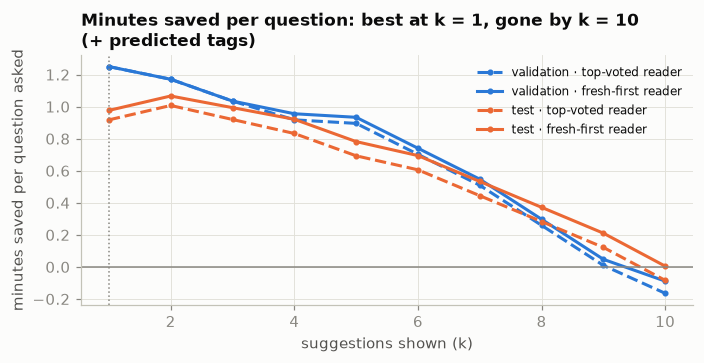

In [16]:
# the operating point: how many suggestions to show, from reading time and minutes saved — chosen on validation
adopted = abl[abl["adopt (valid CI > 0)"].astype(bool)]
CHOSEN = adopted[f"valid recall@{K}"].astype(float).idxmax() if len(adopted) else "BM25 only"
rk_star = RANKS[CHOSEN]
def found_and_stale(sel, policy, kmax=10):
    rows_ = np.flatnonzero(sel)
    lists = [ask(i, k=kmax, policy=policy, cand=rk_star) for i in rows_]
    found = np.full((len(rows_), kmax), False); stale = np.full((len(rows_), kmax), False)
    for j, (i, lst) in enumerate(zip(rows_, lists)):
        for r_, a in enumerate(lst):
            if ids[a["thread_row"]] in REL[i]:
                found[j, r_:] = True; stale[j, r_:] = a_stale[a["answer_row"]]
                break
    return found, stale

def minutes_per_question(found, stale, k):
    """Expected minutes saved per question asked: only SHARE_ANSWERABLE of questions have an earlier answer to find."""
    return (SHARE_ANSWERABLE * (found[:, k - 1].mean() * MIN_SAVED_IF_FOUND - (found[:, k - 1] & stale[:, k - 1]).mean() * MIN_LOST_IF_STALE)
            - k * SEC_PER_SUGGESTION / 60)

ks = np.arange(1, 11)
op = {}
for split_, sel_ in [("validation", val_bc), ("test", test_bc)]:
    for pol in ["top-voted", "fresh-first"]:
        fd, st = found_and_stale(sel_, pol)
        op[(split_, pol)] = [minutes_per_question(fd, st, k) for k in ks]
        if split_ == "test" and pol == "fresh-first":
            fd_test, st_test = fd, st
K_STAR = int(ks[np.argmax(op[("validation", "fresh-first")])])
v_test = op[("test", "fresh-first")][K_STAR - 1]
week_h = v_test * QUESTIONS_PER_WEEK / 60

fig, ax = plt.subplots(figsize=(6.5, 3.4))
for (split_, pol), color, ls in zip(op, [SERIES[0], SERIES[0], SERIES[1], SERIES[1]], ["--", "-", "--", "-"]):
    ax.plot(ks, op[(split_, pol)], ls, marker="o", ms=3, lw=2, color=color, label=f"{split_} · {pol} reader")
ax.axhline(0, color=MUTED, lw=1); ax.axvline(K_STAR, color=MUTED, ls=":", lw=1)
ax.set_xlabel("suggestions shown (k)"); ax.set_ylabel("minutes saved per question asked")
ax.set_title(f"Minutes saved per question: best at k = {K_STAR}, gone by k = 10\n({CHOSEN})"); ax.legend(fontsize=8)
plt.tight_layout()
print(f"k* = {K_STAR} (validation) · test: thread found {fd_test[:, K_STAR - 1].mean():.1%} of answerable questions, "
      f"{v_test:.2f} min saved per question asked → {week_h:.1f} engineer-hours a week (≈ €{week_h * ENGINEER_EUR_PER_HOUR:,.0f}) at {QUESTIONS_PER_WEEK} questions · "
      f"at k = 10: {op[('test', 'fresh-first')][-1]:+.2f} min (test), {op[('validation', 'fresh-first')][-1]:+.2f} (validation)")

Show one suggestion (test would have preferred two, narrowly). At the assumed constants it saves 0.98 minutes per question asked on test, about 2.4 engineer-hours a week (≈ €146); at ten suggestions reading eats the saving. Every term is an assumption (task C3). The CI gates need fingerprinted holdouts and thresholds set on validation:

In [17]:
# what the CI gates will hold fixed: fingerprints of the frozen holdouts, and thresholds set from validation, not from test
fp_gold = hashlib.sha256(gold.loc[test_bc, ["q", "family"]].assign(rel=gold.relevant[test_bc].map(sorted).astype(str)).to_csv(index=False).encode()).hexdigest()
fp_tag = hashlib.sha256(np.ascontiguousarray(Q.id.values[te]).tobytes() + np.ascontiguousarray(Y[te]).tobytes()).hexdigest()
r_boot = (FIRST[CHOSEN][val_bc] <= K).astype(float)
r_boot = r_boot[rng.integers(0, len(r_boot), (1_000, len(r_boot)))].mean(1)
GATES = {"tag micro-F1": tag_res.loc["validation (2014)", "micro-F1"] - GATE_TAG_TOLERANCE,      # 28,792 questions: sampling noise is tiny, period noise is not
         f"pooled recall@{K}": np.quantile(r_boot, 0.025),                                           # 158 queries: the lower 95 % bootstrap bound
         "attribution contract": 1.0}
print(f"golden test set sha256 {fp_gold[:16]}… · tag test set sha256 {fp_tag[:16]}…")
print("gates (set on validation):", {k_: round(float(v_), 3) for k_, v_ in GATES.items()},
      f"· test: micro-F1 {tag_res.loc['test (2015 – Oct 2016)', 'micro-F1']:.3f}, recall@{K} {scores_of(FIRST[CHOSEN], test_bc)[f'recall@{K}']:.3f}")

golden test set sha256 586c9f072372c241… · tag test set sha256 7e1dfede7c2fdfda…
gates (set on validation): {'tag micro-F1': 0.733, 'pooled recall@5': 0.184, 'attribution contract': 1.0} · test: micro-F1 0.750, recall@5 0.229


The tag gate allows 0.02 below validation (a business tolerance: sampling noise on 28,792 questions is tiny); the retrieval gate is the lower bootstrap bound on 158 queries. Test clears both.

# Part C — Productionise it

*Sections 7–10: this is your assignment.*

## 7 · After deployment: the archive drifts under the copilot

*Part C · Productionise · what your monitoring plan must catch; reuse `psi_cat` (C5).*

Three clocks: what people ask, what the frozen tagger predicts (Session 04's PSI against 2014), and how hard retrieval gets as the archive grows.

,micro-F1,PSI of predicted-tag mix,tags outside the label set
2014Q1,0.757,reference,0.442
2014Q2,0.755,reference,0.440
2014Q3,0.750,reference,0.446
2014Q4,0.751,reference,0.459
2015Q1,0.748,0.008,0.465
2015Q2,0.756,0.018,0.475
2015Q3,0.747,0.020,0.470
2015Q4,0.753,0.037,0.475
2016Q1,0.758,0.042,0.481
2016Q2,0.743,0.053,0.484


,2010,2011,2012,2013,2014,2015,2016
recall@5,0.49,0.34,0.33,0.27,0.21,0.27,0.21
n,57,104,119,179,158,215,191
threads in the index,"8,270","18,892","34,397","56,381","85,259","113,927","147,688"


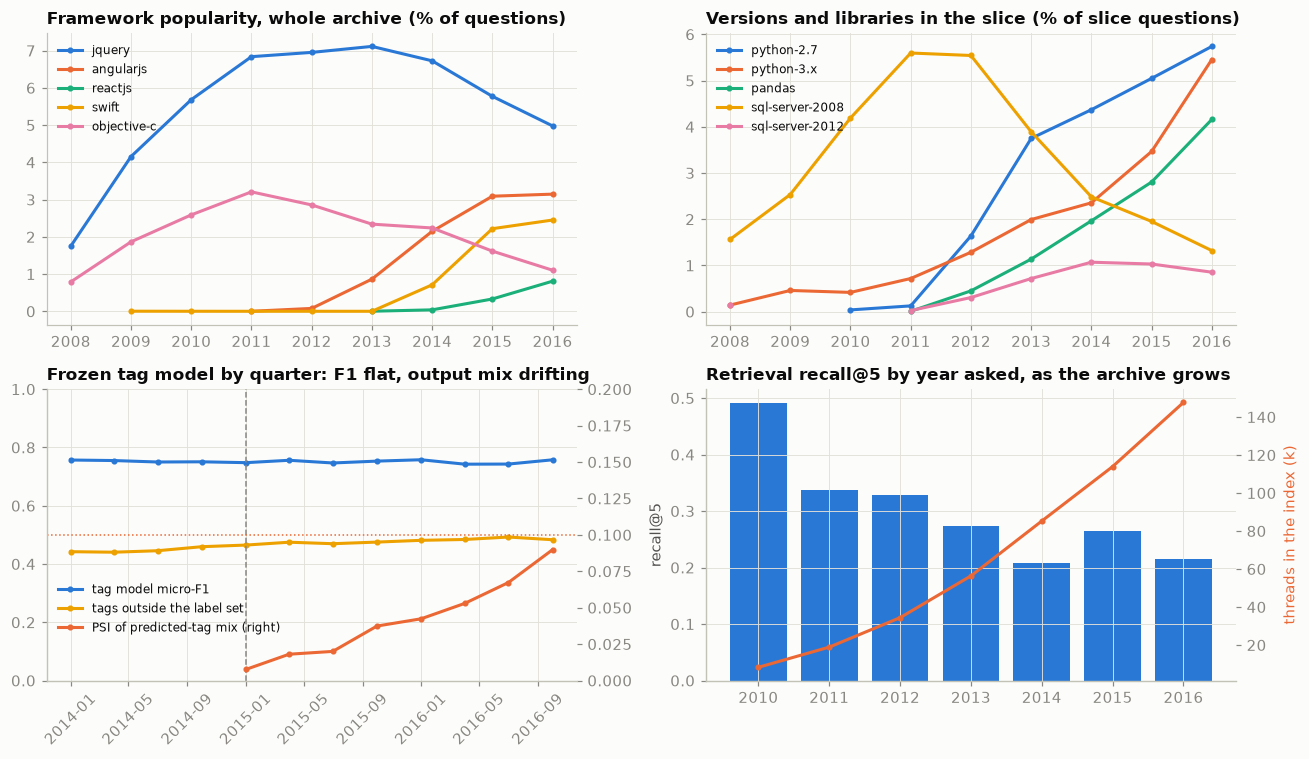

In [18]:
yq = QALL.set_index("id").created.dt.year
tag_year = TAGS.assign(year=yq.reindex(TAGS.id).values)
n_year = yq.value_counts().sort_index()
FRAMEWORKS = ["jquery", "angularjs", "reactjs", "swift", "objective-c"]
fw = tag_year[tag_year.tag.isin(FRAMEWORKS)].groupby(["year", "tag"], observed=True).size().unstack().div(n_year, axis=0) * 100
in_q = set(Q.id)
VERS_SHOW = ["python-2.7", "python-3.x", "pandas", "sql-server-2008", "sql-server-2012"]
sl = tag_year[tag_year.id.isin(in_q) & tag_year.tag.isin(VERS_SHOW)].groupby(["year", "tag"], observed=True).size().unstack()
sl = sl.div(Q.created.dt.year.value_counts().sort_index(), axis=0) * 100

quarter = Q.created.dt.to_period("Q").values
after = va | te
qdf = pd.DataFrame({"q": quarter[after]})
pred_top = LAB[S_tag[after].argmax(1)]
ref_mix = pd.Series(pred_top[va[after]]).value_counts(normalize=True)
def psi_cat(ref, cur, eps=1e-4):
    r, c = ref.align(cur, fill_value=0); r, c = r + eps, c + eps
    return float(np.sum((c - r) * np.log(c / r)))
by_q = pd.DataFrame({
    "micro-F1": [f1_score(Y[after][m], predict_sets(S_tag[after][m], THR_TAG), average="micro") for m in [qdf.q.values == p for p in sorted(set(qdf.q))]],
    "PSI of predicted-tag mix": [psi_cat(ref_mix, pd.Series(pred_top[qdf.q.values == p]).value_counts(normalize=True)) for p in sorted(set(qdf.q))],
}, index=sorted(set(qdf.q)))
cov = thread_tags.assign(q=quarter[rows]).assign(inv=lambda d: d.tag.isin(LABELS))
by_q["tags outside the label set"] = 1 - cov[after[rows]].groupby("q").inv.mean().reindex(by_q.index)
by_q.loc[by_q.index.to_timestamp() < TEST_START, "PSI of predicted-tag mix"] = np.nan   # 2014 is the reference itself: no in-sample alerts

f_all = first_hit(CAND)
bc = gold.family.isin(["linked by an answerer", "cited by the asker"]).values
gy = gold.created.dt.year.values
rec_year = pd.DataFrame({"recall@5": [(f_all[bc & (gy == y)] <= K).mean() for y in range(2010, 2017)],
                         "n": [int((bc & (gy == y)).sum()) for y in range(2010, 2017)],
                         "threads in the index": [int((doc_time < pd.Timestamp(f"{y}-07-01").value // 10**9).sum()) for y in range(2010, 2017)]},
                        index=range(2010, 2017))

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
ax = axes[0, 0]
for t, color in zip(FRAMEWORKS, SERIES):
    ax.plot(fw.index, fw[t], "-o", ms=3, lw=2, color=color, label=t)
ax.set_title("Framework popularity, whole archive (% of questions)"); ax.legend(fontsize=8)
ax = axes[0, 1]
for t, color in zip(VERS_SHOW, SERIES):
    ax.plot(sl.index, sl[t], "-o", ms=3, lw=2, color=color, label=t)
ax.set_title("Versions and libraries in the slice (% of slice questions)"); ax.legend(fontsize=8)
ax = axes[1, 0]
xq = by_q.index.to_timestamp()
ax.plot(xq, by_q["micro-F1"], "-o", ms=3, lw=2, color=SERIES[0], label="tag model micro-F1")
ax.plot(xq, by_q["tags outside the label set"], "-o", ms=3, lw=2, color=SERIES[3], label="tags outside the label set")
ax.set_ylim(0, 1); ax.axvline(TEST_START, color=MUTED, ls="--", lw=1); ax.tick_params(axis="x", rotation=45)
ax2 = ax.twinx(); ax2.plot(xq, by_q["PSI of predicted-tag mix"], "-o", ms=3, lw=2, color=SERIES[1], label="PSI of predicted-tag mix (right)")
ax2.axhline(0.10, color=SERIES[1], ls=":", lw=1); ax2.set_ylim(0, max(0.2, by_q["PSI of predicted-tag mix"].max() * 1.1)); ax2.grid(False)
ax.set_title("Frozen tag model by quarter: F1 flat, output mix drifting")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="lower left", bbox_to_anchor=(0, 0.12))
ax = axes[1, 1]
ax.bar(rec_year.index, rec_year["recall@5"], color=SERIES[0], label=f"recall@{K}")
ax2 = ax.twinx(); ax2.plot(rec_year.index, rec_year["threads in the index"] / 1e3, "-o", ms=3, lw=2, color=SERIES[1]); ax2.grid(False)
ax2.set_ylabel("threads in the index (k)", color=SERIES[1])
ax.set_title(f"Retrieval recall@{K} by year asked, as the archive grows"); ax.set_ylabel(f"recall@{K}")
plt.tight_layout()
display(by_q.style.format("{:.3f}", na_rep="reference"))
display(rec_year.T.style.format("{:.2f}", subset=pd.IndexSlice[["recall@5"], :]).format("{:,.0f}", subset=pd.IndexSlice[["n", "threads in the index"], :]))

Frameworks turn over: jQuery peaks in 2013, Swift overtakes Objective-C after 2014, React takes off in 2015. In the slice, `python-3.x` nearly catches `python-2.7` by 2016, pandas more than triples from 2013, and `sql-server-2008` falls to a quarter of its peak. The frozen tagger's micro-F1 holds at 0.74–0.76, as Trap 1 predicts. What moves is the predicted-tag mix (PSI against 2014: 0.008 in 2015Q1, 0.07 in Q3 2016, 0.09 in the partial last quarter) and the share of tags outside the label set (44 % → 49 %). Retrieval degrades on its own clock: recall@5 falls from 0.49 for 2010's questions to 0.21 for 2016's as the index grows from 8,000 to 148,000 threads (57–215 queries a year: read the trend). Monitor the output mix, new tags and retrieval against archive size; the headline metric will not move.

**The answer to the board.** The copilot's single suggestion is the thread a colleague pointed to for 13.8 % of answerable test questions (23 % within five). Every shown answer carries post links, an author profile link and the licence with its URI; names must still be fetched at render time. The fresh-first reader cuts answers using a removed API from 9.1 % to 5.7 %. At the assumed constants it saves about 2.4 engineer-hours a week: worth a pilot that measures `SHARE_ANSWERABLE`, not a roll-out.

## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

A cleaner, a tagger, an index, a reader with a citation contract and a knowledge graph, each needing the unit's operational treatment. Updated with this notebook's findings:

| Spine | In this project |
|---|---|
| Package and container (S02–S03) | `src/dev_copilot/` (cleaning, tagger, index, reader, `kb/`); `POST /ask` returns each suggestion with its attribution fields and `stale_api`; `POST /tags`; compose with Postgres |
| Monitoring (S04) | RED metrics. Attribution contract (100 %; names 0 % until fetched). Answers using a removed API (5.7 %). Source age (median 1.7 years). Predicted-tag PSI vs 2014 (alert 0.10; 0.09 by Oct 2016). Tags outside the label set (44 → 49 %). Cost per answer |
| CI/CD gate (S05) | On fingerprinted holdouts: tag micro-F1 ≥ 0.733 (test 0.750); pooled recall@5 ≥ 0.184 (test 0.229); attribution contract (post links, author profile, licence with URI); query-cleaning and as-of tests |
| MLflow tracking and registry (S06) | Tagger runs (labels, threshold, data and holdout SHA-256); retriever configuration (fields, β, λ, *k*, reader policy); KB version; `champion`/`challenger`; prompt versions with S1 |
| Offline / online training and serving | Index and KB rebuilt nightly; online answers; tagger retrained quarterly or on a tag-mix alert |
| Data and model drift | Version turnover; predicted-tag PSI to 0.09; versioned-tag F1 falling (`sql-server-2005` 0.34 → 0.24); recall@5 0.49 → 0.21 as the index grows 18-fold |
| Knowledge base and context (S07–S09) | Tag graph, 34 version tags under 16 libraries, 3 dated removed-API facts. Retrieval-side components lose on test (−1.2, −3.0, −2.7 points); the fresh-first reader cuts stale top answers 9.1 % → 5.7 % |
| GenAI and context engineering (S10–S11) | RAG over the top threads' answers, a citation per claim, refusal on stale or conflicting sources; golden-set, citation and groundedness regression |
| Governance | CC BY-SA 3.0 §4 and Stack Overflow's guidance: post link, author name and profile, licence with URI on every shown answer; names fetched at render time (not in the data). Share-alike for LLM summaries is a question for counsel (E2). User IDs are personal data (the team's reading of GDPR Recital 26); e-mails and credentials masked |

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S1**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap, with a test.** Tests fail if a duplicate notice, a question link or raw HTML reaches the retriever, if a suggestion or answer postdates the question, or if an answer lacks its post link, author profile or licence URI. Add the display-name lookup at render time, without storing names. Report the tagger per versioned tag.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the operating point.** Vary `SHARE_ANSWERABLE` (0.1–0.5) and the minute constants; show how *k* and weekly hours move, find the break-even, write the ADR, and say how you would measure `SHARE_ANSWERABLE`.
- **C4 — Package, container and gates.** `POST /ask`, `POST /tags`, Dockerfile, compose, and `make ci` with the three gates on the fingerprinted holdouts, refusing to run if a fingerprint changes (Sessions 02, 03, 05).
- **C5 — Register, document, monitor.** MLflow runs, `champion`/`challenger` aliases, a model card (licence, user IDs, 10 % sample, incomplete golden set, removed-API facts) and a monitoring plan with this notebook's signals and triggers (Sessions 04, 06).

### Extension

- **E1 — The knowledge-base ablation, done properly.** SKOS tags, versions with release dates, removed APIs with `deprecatedIn`/`removedIn`, validated with SHACL; re-run the ablation per component (Sessions 07–09).
- **E2 — Licence and data-protection position.** What CC BY-SA 3.0 requires for a verbatim answer, an excerpt, or an LLM summary of several answers, as questions for counsel plus your reading; how display names are fetched and cached; the GDPR position on user IDs and names.
- **E3 — A real duplicate golden set.** Build one from the full Stack Exchange dump's duplicate links and report how much the 10 % sample understates recall.
- **E4 — Version-aware answers from the knowledge layer.** Read the version a question targets from its tags and the KB's version facts (no new classifier) and prefer answers for it at the reader; measure stale share, recall, and whether Python 2 and 3 askers are served equally.

### Stretch

- **S1 — RAG with licence-compliant citations.** An LLM over the top threads' answers, behind a versioned prompt that cites answer, author and licence per claim and refuses on stale or conflicting sources. Evaluate citation precision, groundedness (judge calibrated on 50 hand-labelled answers), stale-API rate and cost on the golden set (Sessions 10–11).
- **S2 — Online serving and its cost.** Serve `POST /ask` from memory or Postgres full-text search; measure p95 latency at 150 questions a week and at 100×; cost re-indexing and S1 calls per month.
- **S3 — A golden set that grows with use.** Log which suggestion helped; extend the golden set without the copilot grading its own homework.

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Session 02 layout; fresh-clone test passes; `data/` not committed; fixture text attributed
- [ ] `README.md`: slice, splits, source (Kaggle, CC BY-SA 3.0)
- [ ] Traps fixed with tests: query cleaning, as-of rule, attribution contract, fresh-first reader, dead ends
- [ ] Operating point chosen on validation from the cost constants, with the ADR
- [ ] `make ci` with three gates on fingerprinted holdouts; registry; model card; monitoring plan
- [ ] Knowledge-base ablation with SHACL validation
- [ ] One-page recommendation to the engineering manager: hits, reading cost, staleness, licence position
- [ ] Required tasks done: C1–C5, E1–E4 and S1
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, what you rejected, what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `scikit-learn`, `scipy`, `networkx`, `rank-bm25`, `matplotlib`, `kagglehub` (pinned). No LLM in the baseline.
- Stack Overflow (via Kaggle). *StackSample: 10% of Stack Overflow Q&A* (CC BY-SA 3.0).
- Creative Commons. *Attribution-ShareAlike 3.0 Unported*, legal code, Section 4.
- Atwood, J. (2009). *Attribution Required.* Stack Overflow blog, 25 June 2009.
- PHP manual (original MySQL extension deprecated in 5.5.0, removed in 7.0.0); PEP 373 (Python 2.7 end of life); pandas 0.20.0 and 1.0.0 release notes (`.ix`).
- Robertson, S., Zaragoza, H. (2009). *The Probabilistic Relevance Framework: BM25 and Beyond.*
- Zhang, M.-L., Zhou, Z.-H. (2014). *A Review on Multi-Label Learning Algorithms.* IEEE TKDE.
- Huyen, C. (2024). *AI Engineering*, Ch. 6 (RAG). Regulation (EU) 2016/679 (GDPR), Recital 26.

In [19]:
from importlib.metadata import version
import matplotlib
print(f"python packages: pandas {pd.__version__} · numpy {np.__version__} · scikit-learn {sklearn.__version__} · networkx {nx.__version__} · "
      f"pyarrow {pa.__version__} · rank-bm25 {version('rank-bm25')} · matplotlib {matplotlib.__version__}")
print(f"notebook finished · total wall time {time.time()-T_START:.0f}s")

python packages: pandas 3.1.0 · numpy 2.5.4 · scikit-learn 1.9.1 · networkx 3.7 · pyarrow 26.0.0 · rank-bm25 0.2.2 · matplotlib 3.11.2
notebook finished · total wall time 112s
